# OLIST-3 · Transformar os números em achados de negócio

**Tech Challenge Agentic AI — Fase 1 (FIAP)** · Responsável: Igor · Grupo: Diogo, Igor e Lorran

**O que o enunciado pede:** o relatório deve trazer os *principais problemas ou oportunidades identificadas* e as *análises realizadas no dataset* (Enunciado, p. 7). O grupo é avaliado pela *profundidade das análises e qualidade dos insights* (critério 4, p. 5).

**Objetivo deste notebook:** transformar os indicadores do OLIST-2 em achados que mostrem **onde estão os problemas e as oportunidades** da Olist. Esses achados justificam a escolha dos agentes nos próximos cards:
- OLIST-5: matriz de oportunidades;
- OLIST-6: KPIs;
- OLIST-8: mapa de agentes;
- OLIST-4: gráficos do relatório.

**Ponto de partida:** a base de pedidos do OLIST-2 (`data/processed/base_pedidos.csv`), com as 8 regras de qualidade já aplicadas. Rode o notebook 01 antes deste.

## Como ler cada achado
Toda análise termina em um quadro com quatro partes:

| Parte | Pergunta que responde | Exemplo |
|---|---|---|
| **Fato** | O que os números mostram, sem opinião? | "61% dos pedidos atrasados recebem nota 1 ou 2" |
| **Leitura** | O que isso sugere sobre o negócio? | "o atraso aparece junto com a insatisfação" |
| **Cautela** | Até onde podemos ir com esse dado? | "é associação: o dado não prova que o atraso é o motivo da nota" |
| **E daí?** | O que muda para a Olist e para os agentes? | "agir antes do atraso protege a nota" |

**Linguagem:** os dados são observacionais, então nenhum achado afirma causa. Usamos "associado a", "aparece junto com" e "compatível com". A Etapa 4 confere isso automaticamente (CA4).

**Rastreabilidade:** todo número citado vem de uma **métrica** (M01, M02…). Cada métrica tem fórmula do Excel na planilha `reports/achados_olist3.xlsx`, que usa a mesma lógica da planilha do OLIST-2 (CA6).

| Etapa | O que sai dela | Critério de aceite |
|---|---|---|
| 0. Preparação | base de análise com 1 linha por pedido e colunas novas | — |
| 1. Análises núcleo (N1–N6) | atraso × nota, origem das notas negativas, temas dos comentários, cancelamentos, recompra, estados | CA1, CA3 |
| 2. Análises diferenciais (D1–D6) | etapa do atraso, vendedores, categoria e peso, frete e pagamento, sazonalidade, distância | CA2, CA3 |
| 3. Achados-chave | 4 a 6 achados em ordem de relevância, cada um ligado a um desafio do enunciado | CA5, CA7 |
| 4. Checagens e exportação | cobertura de dimensões, linguagem, Excel, JSON e figuras | CA1, CA4, CA6 |

## Etapa 0 · Preparação

In [1]:
import sys
import unicodedata
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

from olist import config, io, viz
from olist.viz import fmt_int, fmt_pct
from olist.indicators import IndicatorBook
from olist.findings import FindingBook, DESAFIOS
from olist.export import to_excel

viz.setup()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def br(x, d=1):
    """Número no formato brasileiro (vírgula decimal)."""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

### Base de análise
Partimos da base de pedidos do OLIST-2 e acrescentamos, sempre com **1 linha por pedido**, as colunas que as análises precisam:

| Coluna nova | O que é | Regra usada |
|---|---|---|
| `seller_id`, `seller_state`, `categoria` | vendedor, UF do vendedor e categoria do item de maior preço do pedido | R1: o pedido continua sendo uma linha |
| `peso_total_g`, `frete_pct` | peso somado dos itens; frete ÷ (preço + frete) | R5: vazio continua vazio |
| `aprovacao_dias`, `postagem_dias`, `transporte_dias`, `prazo_prometido_dias` | tempo de cada etapa do ciclo do pedido | R4 e R6: só para entregues válidos, sem etapa negativa |
| `postou_fora_limite` | 1 se o vendedor postou depois do prazo-limite de postagem | R4 |
| `mesma_uf`, `distancia_km` | cliente e vendedor no mesmo estado; distância em linha reta entre os CEPs | R7: 1 ponto por CEP |
| `regiao`, `faixa_*` | agrupamentos para tabelas | — |
| `nota_negativa`, `tema_*` | nota 1 ou 2; temas encontrados no comentário | R3: 1 avaliação por pedido |
| `pagamento`, `parcelas` | meio de pagamento principal e número de parcelas | R8 |
| `n_pedidos_cliente`, `primeira_compra` | quantos pedidos o cliente fez; se este é o primeiro dele | R2: cliente = `customer_unique_id` |

In [2]:
t = io.load_all()
base = pd.read_csv(config.PROCESSED / "base_pedidos.csv", dtype={"customer_state": "string"},
                   parse_dates=["data_compra", "data_entrega", "data_prometida"])
orders, items, products, sellers = t["orders"], t["order_items"], t["products"], t["sellers"]
payments, reviews, geo = t["payments"], t["order_reviews"], t["geolocation"]

# item principal (maior preço) de cada pedido -> vendedor e categoria do pedido
it = items.merge(products[["product_id", "product_category_name", "product_weight_g"]], on="product_id", how="left")
principal = (it.sort_values(["order_id", "price"], ascending=[True, False]).drop_duplicates("order_id")
               [["order_id", "seller_id", "product_category_name"]].rename(columns={"product_category_name": "categoria"}))
principal = principal.merge(sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]], on="seller_id", how="left")
peso = it.groupby("order_id").agg(peso_total_g=("product_weight_g", lambda s: s.sum(min_count=len(s))),
                                  limite_postagem=("shipping_limit_date", "max"))

# etapas do ciclo
o = orders.set_index("order_id")
dias = lambda a, b: (o[b] - o[a]).dt.total_seconds() / 86400
etapas = pd.DataFrame({
    "aprovacao_dias": dias("order_purchase_timestamp", "order_approved_at"),
    "postagem_dias": dias("order_approved_at", "order_delivered_carrier_date"),
    "transporte_dias": dias("order_delivered_carrier_date", "order_delivered_customer_date"),
    "prazo_prometido_dias": dias("order_purchase_timestamp", "order_estimated_delivery_date"),
    "aprovado": o["order_approved_at"].notna().astype(int),
    "data_postagem": o["order_delivered_carrier_date"],
}).reset_index()

# pagamento principal (maior valor) e parcelas
pag = (payments.sort_values(["order_id", "payment_value"], ascending=[True, False]).drop_duplicates("order_id")
               [["order_id", "payment_type", "payment_installments"]].rename(columns={"payment_type": "pagamento", "payment_installments": "parcelas"}))

# geolocalização: 1 ponto por CEP (regra R7)
dentro_br = geo["geolocation_lat"].between(-34, 5.5) & geo["geolocation_lng"].between(-74, -34)
geo_cep = geo[dentro_br].groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
cli_cep = t["customers"][["customer_unique_id", "customer_zip_code_prefix"]].drop_duplicates("customer_unique_id")

a = (base.merge(principal, on="order_id", how="left").merge(peso.reset_index(), on="order_id", how="left")
         .merge(etapas, on="order_id", how="left").merge(pag, on="order_id", how="left"))
# CEP do cliente vem do pedido (customer_id) para não misturar endereços de compras diferentes
cep_pedido = orders[["order_id", "customer_id"]].merge(t["customers"][["customer_id", "customer_zip_code_prefix"]], on="customer_id")
a = a.merge(cep_pedido[["order_id", "customer_zip_code_prefix"]], on="order_id", how="left")

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))

pc = geo_cep.reindex(a["customer_zip_code_prefix"]).to_numpy()
ps = geo_cep.reindex(a["seller_zip_code_prefix"]).to_numpy()
a["distancia_km"] = haversine(pc[:, 0], pc[:, 1], ps[:, 0], ps[:, 1]).round(0)

valido = a["entregue_valido"] == 1
for c in ["aprovacao_dias", "postagem_dias", "transporte_dias", "prazo_prometido_dias"]:
    a[c] = a[c].where(valido & (a[c] >= 0)).round(2)              # R4 + R6: só entregues válidos, sem etapa negativa
a["postou_fora_limite"] = (a["data_postagem"] > a["limite_postagem"]).astype(float).where(valido & a["data_postagem"].notna())
a["mesma_uf"] = (a["seller_state"] == a["customer_state"]).astype(float).where(a["seller_state"].notna())
a["frete_pct"] = (a["valor_frete"] / (a["valor_itens"] + a["valor_frete"])).round(4)

REGIAO = {**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Norte"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centro-Oeste"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"),
          **dict.fromkeys(["PR", "RS", "SC"], "Sul")}
a["regiao"] = a["customer_state"].map(REGIAO)

a["faixa_atraso"] = pd.cut(a["atraso_dias"], [-np.inf, 0, 3, 7, 14, np.inf],
                           labels=["a. no prazo", "b. 1-3 dias", "c. 4-7 dias", "d. 8-14 dias", "e. 15+ dias"]).astype("string")
a["faixa_peso"] = pd.cut(a["peso_total_g"], [-1, 500, 2000, 5000, 10000, np.inf],
                         labels=["a. até 0,5 kg", "b. 0,5-2 kg", "c. 2-5 kg", "d. 5-10 kg", "e. mais de 10 kg"]).astype("string")
a["faixa_distancia"] = pd.cut(a["distancia_km"], [-1, 100, 500, 1000, 2000, np.inf],
                              labels=["a. até 100 km", "b. 100-500 km", "c. 500-1.000 km", "d. 1.000-2.000 km", "e. mais de 2.000 km"]).astype("string")
a["faixa_frete"] = pd.qcut(a["frete_pct"], 5, labels=["q1 (menor frete)", "q2", "q3", "q4", "q5 (maior frete)"]).astype("string")

a["nota_negativa"] = a["review_score"].isin([1, 2]).astype(float).where(a["review_score"].notna())
cli = a.groupby("customer_unique_id")["order_id"].transform("count")
a["n_pedidos_cliente"] = cli
a["primeira_compra"] = (a.sort_values("data_compra").groupby("customer_unique_id").cumcount() == 0).reindex(a.index).astype(int)
print(f"base de análise: {fmt_int(len(a))} pedidos × {a.shape[1]} colunas")

base de análise: 99.441 pedidos × 46 colunas


### Temas dos comentários negativos
Para saber **do que** o cliente insatisfeito reclama, classificamos os comentários das avaliações com nota 1 ou 2 por **palavras-chave**. Seis temas foram definidos lendo uma amostra dos textos.

Um comentário pode ter mais de um tema. Essa classificação é aproximada: ela erra ironias e frases fora do padrão. Um modelo de linguagem faria melhor, e essa é justamente uma oportunidade para um agente de IA.

In [3]:
TEMAS = {
    "tema_nao_recebeu": r"nao (recebi|chegou|foi entregue|entreg|veio)|ainda nao (recebi|chegou)|nunca (chegou|recebi)|nao havia recebido|aguardando",
    "tema_atraso": r"atras|demor|prazo|lent|esper",
    "tema_produto_errado": r"errad|diferente|faltou|falta|faltando|incomplet|so (veio|recebi|chegou)|apenas (um|uma|1)|outro produto|veio outro|trocad|nao condiz",
    "tema_defeito_qualidade": r"defeit|quebr|danific|qualidade|nao funciona|parou de funcionar|ruim|pessim|riscad|amassad|falsificad|original|estrag|nao faz efeito",
    "tema_atendimento": r"atendimento|contato|respond|resposta|\bsac\b|reclam|e-?mail|telefone|ninguem",
    "tema_cancelamento_reembolso": r"cancel|estorn|reembols|devol|dinheiro de volta|troca",
}
NOME_TEMA = {"tema_nao_recebeu": "Não recebeu o produto", "tema_atraso": "Atraso na entrega",
             "tema_produto_errado": "Produto errado ou incompleto", "tema_defeito_qualidade": "Defeito ou qualidade",
             "tema_atendimento": "Atendimento e contato", "tema_cancelamento_reembolso": "Cancelamento, troca ou reembolso"}

rev_ped = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
                  .drop_duplicates("order_id", keep="last")[["order_id", "review_comment_message"]])   # R3
a = a.merge(rev_ped, on="order_id", how="left")
norm = lambda s: unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
txt = a["review_comment_message"].astype("string").str.strip()
neg_txt = (a["nota_negativa"] == 1) & txt.notna() & (txt != "")
texto = txt.where(neg_txt).dropna().map(norm)
for col, padrao in TEMAS.items():
    a[col] = np.nan
    a.loc[texto.index, col] = texto.str.contains(padrao, regex=True).astype(float)
a["tema_entrega"] = a[["tema_nao_recebeu", "tema_atraso"]].max(axis=1)       # qualquer tema de entrega
a["tema_produto"] = a[["tema_produto_errado", "tema_defeito_qualidade"]].max(axis=1)
a = a.drop(columns=["review_comment_message"])
print(f"{fmt_int(neg_txt.sum())} comentários negativos classificados")
a.loc[neg_txt, list(TEMAS) + ["tema_entrega", "tema_produto"]].mean().rename(NOME_TEMA).sort_values(ascending=False)

10.838 comentários negativos classificados


C:\Users\igor_\AppData\Local\Temp\ipykernel_1856\1994452319.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  a.loc[texto.index, col] = texto.str.contains(padrao, regex=True).astype(float)
C:\Users\igor_\AppData\Local\Temp\ipykernel_1856\1994452319.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  a.loc[texto.index, col] = texto.str.contains(padrao, regex=True).astype(float)


tema_entrega                       0.452
Não recebeu o produto              0.327
tema_produto                       0.316
Produto errado ou incompleto       0.188
Atraso na entrega                  0.183
Defeito ou qualidade               0.145
Cancelamento, troca ou reembolso   0.142
Atendimento e contato              0.135
dtype: float64

In [4]:
book = IndicatorBook()     # métricas com fórmula Excel (M01, M02, ...)
fb = FindingBook()         # achados no formato Fato · Leitura · Cautela · E daí?
ent = a[a["entregue_valido"] == 1]
M = lambda i: next(m for m in book.items if m.id == i)   # atalho para ler uma métrica já registrada

## Etapa 1 · Análises núcleo
São as análises que o próprio enunciado sugere ao citar os desafios da Olist (p. 2): entrega, avaliações, cancelamentos, recompra e região.

### N1 · Atraso × nota
**Pergunta:** a nota do cliente muda quando o pedido chega atrasado? E quanto mais atrasado, pior?

M01 · % de notas negativas: atrasados × no prazo: 62,4%


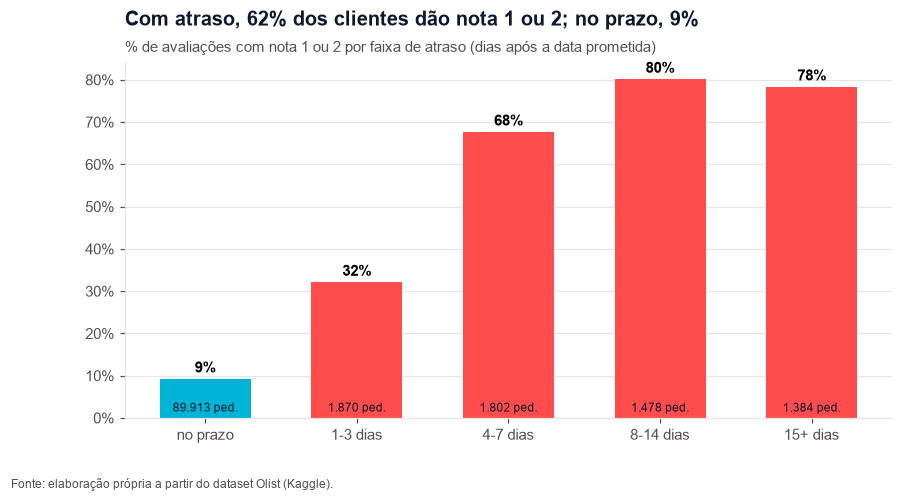

#### N1 · O atraso aparece junto com a insatisfação, e a parte de notas ruins cresce com os dias de atraso até cerca de uma semana

*Pergunta:* A nota do cliente muda quando o pedido chega atrasado?  
*Tipo:* análise núcleo · *Dimensões:* pedidos, logística, avaliações · *Desafios do enunciado:* Experiência do cliente, Eficiência logística, Gestão de avaliações (reviews) · *Métricas na planilha:* M01

| | |
|---|---|
| **Fato** | Entre os pedidos entregues com atraso, 62,4% receberam nota 1 ou 2; entre os entregues no prazo, 9,3%. A parte de notas negativas sobe de 32% (1 a 3 dias de atraso) para 68% (4 a 7 dias) e fica perto de 79% a partir de 8 dias. |
| **Leitura** | A pontualidade está fortemente associada à satisfação: o cliente que recebe no prazo raramente avalia mal, e o que espera além do prometido avalia mal na maioria das vezes. |
| **Cautela** | É associação: pedidos atrasados podem ter outras características (região, produto, vendedor) que também pesam na nota. A avaliação depende de o cliente responder a pesquisa. |
| **E daí?** | Proteger o prazo, ou avisar o cliente antes de o atraso acontecer, é uma das alavancas mais claras para a nota. É aqui que um agente de acompanhamento de entregas ganha sentido. |


In [5]:
neg_atr, neg_prazo = ent.loc[ent.atrasado == 1, "nota_negativa"].mean(), ent.loc[ent.atrasado == 0, "nota_negativa"].mean()
tab = (ent.groupby("faixa_atraso").agg(pedidos=("order_id", "count"), nota_media=("review_score", "mean"),
                                        pct_negativa=("nota_negativa", "mean")).reset_index())
book.add(id="M01", nome="% de notas negativas: atrasados × no prazo",
         definicao="Parte dos pedidos avaliados com nota 1 ou 2, separando os entregues com atraso dos entregues no prazo.",
         formula="Pedidos atrasados com nota 1–2 ÷ pedidos atrasados avaliados (e o mesmo para os no prazo).",
         tabelas="orders, order_reviews", regras="R3, R4, R6", valor=neg_atr, unidade="%", esperados=[neg_atr, neg_prazo],
         codigo='ent.groupby("atrasado").nota_negativa.mean()',
         excel={"atrasados": "AVERAGEIFS({base:nota_negativa},{base:atrasado},1)",
                "no prazo": "AVERAGEIFS({base:nota_negativa},{base:atrasado},0)"},
         tabela=tab, excel_linhas={"pedidos": "COUNTIFS({base:faixa_atraso},{cell:faixa_atraso})",
                                   "nota_media": "AVERAGEIFS({base:review_score},{base:faixa_atraso},{cell:faixa_atraso})",
                                   "pct_negativa": "AVERAGEIFS({base:nota_negativa},{base:faixa_atraso},{cell:faixa_atraso})"})

fig, ax = plt.subplots(figsize=(9, 4.2))
cores = [viz.SERIES[0]] + [viz.SERIES[1]] * (len(tab) - 1)
ax.bar(tab["faixa_atraso"].str[3:], tab["pct_negativa"], color=cores, width=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
for x, (v, n) in enumerate(zip(tab["pct_negativa"], tab["pedidos"])):
    ax.text(x, v + 0.015, fmt_pct(v, 0), ha="center", fontsize=10, fontweight="bold")
    ax.text(x, 0.015, f"{fmt_int(n)} ped.", ha="center", fontsize=8, color=viz.NAVY)
viz.titles(ax, f"Com atraso, {fmt_pct(neg_atr, 0)} dos clientes dão nota 1 ou 2; no prazo, {fmt_pct(neg_prazo, 0)}",
           "% de avaliações com nota 1 ou 2 por faixa de atraso (dias após a data prometida)")
viz.save(fig, "o3_n1_atraso_nota")
plt.show()

fb.add(id="N1", tipo="núcleo", titulo="O atraso aparece junto com a insatisfação, e a parte de notas ruins cresce com os dias de atraso até cerca de uma semana",
       pergunta="A nota do cliente muda quando o pedido chega atrasado?",
       dimensoes=["pedidos", "logística", "avaliações"], desafios=["cliente", "logistica", "reviews"], metricas=["M01"], figura="o3_n1_atraso_nota",
       fato=f"Entre os pedidos entregues com atraso, {fmt_pct(neg_atr)} receberam nota 1 ou 2; entre os entregues no prazo, {fmt_pct(neg_prazo)}. "
            f"A parte de notas negativas sobe de {fmt_pct(tab.pct_negativa.iloc[1], 0)} (1 a 3 dias de atraso) para {fmt_pct(tab.pct_negativa.iloc[2], 0)} (4 a 7 dias) e fica perto de {fmt_pct(tab.pct_negativa.iloc[3:].mean(), 0)} a partir de 8 dias.",
       leitura="A pontualidade está fortemente associada à satisfação: o cliente que recebe no prazo raramente avalia mal, e o que espera além do prometido avalia mal na maioria das vezes.",
       cautela="É associação: pedidos atrasados podem ter outras características (região, produto, vendedor) que também pesam na nota. A avaliação depende de o cliente responder a pesquisa.",
       e_dai="Proteger o prazo, ou avisar o cliente antes de o atraso acontecer, é uma das alavancas mais claras para a nota. É aqui que um agente de acompanhamento de entregas ganha sentido.")

### N2 · De onde vêm as notas negativas
**Pergunta:** que parte das avaliações ruins está ligada a problemas de entrega, como atraso ou pedido não entregue?

In [6]:
n_neg = (a["nota_negativa"] == 1).sum()
de_atraso = ((a["nota_negativa"] == 1) & (a["atrasado"] == 1)).sum() / n_neg
nao_entregue = ((a["nota_negativa"] == 1) & (a["entregue_valido"] == 0)).sum() / n_neg
peso_atrasados = ent["atrasado"].mean()
tab = pd.DataFrame({"origem": ["entregue no prazo", "entregue com atraso", "não entregue ou sem data válida"],
                    "codigo_atrasado": [0, 1, np.nan]})
tab["notas_negativas"] = [((a.nota_negativa == 1) & (a.atrasado == 0)).sum(), ((a.nota_negativa == 1) & (a.atrasado == 1)).sum(),
                          ((a.nota_negativa == 1) & (a.entregue_valido == 0)).sum()]
tab["pct"] = tab["notas_negativas"] / n_neg
book.add(id="M02", nome="Origem das notas negativas",
         definicao="Parte das avaliações com nota 1 ou 2 que vêm de pedidos atrasados e de pedidos não entregues.",
         formula="Notas 1–2 de pedidos atrasados ÷ total de notas 1–2 (e o mesmo para os não entregues).",
         tabelas="orders, order_reviews", regras="R3, R4, R6", valor=de_atraso, unidade="%",
         esperados=[de_atraso, nao_entregue, peso_atrasados],
         codigo='((a.nota_negativa == 1) & (a.atrasado == 1)).sum() / (a.nota_negativa == 1).sum()',
         excel={"de atrasados": "COUNTIFS({base:nota_negativa},1,{base:atrasado},1)/COUNTIF({base:nota_negativa},1)",
                "de não entregues": "COUNTIFS({base:nota_negativa},1,{base:entregue_valido},0)/COUNTIF({base:nota_negativa},1)",
                "atrasados no total": "SUM({base:atrasado})/SUM({base:entregue_valido})"},
         tabela=tab.drop(columns="codigo_atrasado"))

fb.add(id="N2", tipo="núcleo", titulo="Problemas de entrega respondem por uma fatia grande das notas ruins, muito maior que o seu peso nos pedidos",
       pergunta="Que parte das avaliações negativas está ligada a atraso ou a pedido não entregue?",
       dimensoes=["pedidos", "logística", "avaliações"], desafios=["reviews", "logistica"], metricas=["M02"],
       fato=f"Os pedidos atrasados são {fmt_pct(peso_atrasados)} dos entregues, mas concentram {fmt_pct(de_atraso)} de todas as notas 1 ou 2. "
            f"Outros {fmt_pct(nao_entregue)} das notas negativas vêm de pedidos que não foram entregues ou não têm data de entrega válida.",
       leitura=f"Somando atraso e não entrega, cerca de {fmt_pct(de_atraso + nao_entregue, 0)} das avaliações ruins estão ligadas à entrega. O restante passa por produto, atendimento e outros motivos, vistos em N3.",
       cautela="Um pedido entregue no prazo também pode ter tido problema de entrega, como produto danificado no transporte. Por isso a fatia ligada à entrega tende a estar subestimada, e não superestimada.",
       e_dai="Melhorar a entrega atinge a maior parte do problema de reputação, mas não todo. A outra parte pede olhar o conteúdo dos comentários (N3).")

M02 · Origem das notas negativas: 27,5%


#### N2 · Problemas de entrega respondem por uma fatia grande das notas ruins, muito maior que o seu peso nos pedidos

*Pergunta:* Que parte das avaliações negativas está ligada a atraso ou a pedido não entregue?  
*Tipo:* análise núcleo · *Dimensões:* pedidos, logística, avaliações · *Desafios do enunciado:* Gestão de avaliações (reviews), Eficiência logística · *Métricas na planilha:* M02

| | |
|---|---|
| **Fato** | Os pedidos atrasados são 6,8% dos entregues, mas concentram 27,5% de todas as notas 1 ou 2. Outros 15,4% das notas negativas vêm de pedidos que não foram entregues ou não têm data de entrega válida. |
| **Leitura** | Somando atraso e não entrega, cerca de 43% das avaliações ruins estão ligadas à entrega. O restante passa por produto, atendimento e outros motivos, vistos em N3. |
| **Cautela** | Um pedido entregue no prazo também pode ter tido problema de entrega, como produto danificado no transporte. Por isso a fatia ligada à entrega tende a estar subestimada, e não superestimada. |
| **E daí?** | Melhorar a entrega atinge a maior parte do problema de reputação, mas não todo. A outra parte pede olhar o conteúdo dos comentários (N3). |


### N3 · Temas dos comentários negativos
**Pergunta:** quando o cliente dá nota 1 ou 2 e escreve um comentário, do que ele reclama?

M03 · Temas dos comentários negativos: 45,2%


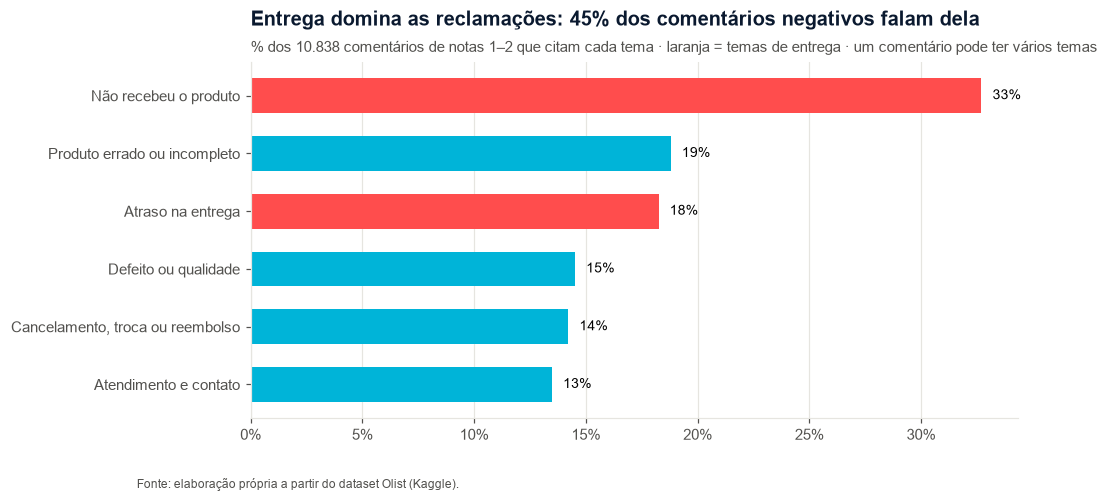

#### N3 · Os comentários negativos falam primeiro de entrega e, em seguida, de produto errado ou com defeito

*Pergunta:* Do que o cliente insatisfeito reclama quando escreve?  
*Tipo:* análise núcleo · *Dimensões:* avaliações, logística, produtos · *Desafios do enunciado:* Gestão de avaliações (reviews), Automação de processos, Experiência do cliente · *Métricas na planilha:* M03

| | |
|---|---|
| **Fato** | Dos 10.838 comentários de avaliações com nota 1 ou 2, 45% citam entrega (não recebeu ou atraso) e 32% citam o produto (errado, incompleto, com defeito ou de má qualidade). Atendimento aparece em 13% e cancelamento, troca ou reembolso em 14%. |
| **Leitura** | O texto confirma o que os números de prazo mostram (N1, N2) e acrescenta um segundo bloco de problemas, ligado ao produto e ao vendedor, que o prazo não explica. |
| **Cautela** | A classificação por palavras-chave é aproximada: erra ironias e frases fora do padrão e não pega todos os casos. Só uma parte dos clientes escreve comentário, então o retrato pode pender para os mais insatisfeitos. |
| **E daí?** | Há milhares de textos em português esperando leitura. Classificar, priorizar e encaminhar esses comentários automaticamente é um caso típico de IA generativa, com ganho de escala para o atendimento. |


In [7]:
cols_t = list(TEMAS)
tab = pd.DataFrame({"tema": [NOME_TEMA[c] for c in cols_t], "coluna": cols_t,
                    "pct_comentarios": [a[c].mean() for c in cols_t]}).sort_values("pct_comentarios", ascending=False, ignore_index=True)
n_coment = int(a["tema_atraso"].notna().sum())
book.add(id="M03", nome="Temas dos comentários negativos",
         definicao="Parte dos comentários de avaliações com nota 1 ou 2 que citam cada tema (um comentário pode ter vários temas).",
         formula="Comentários negativos com o tema ÷ comentários negativos com texto.",
         tabelas="order_reviews", regras="R3, R5", valor=a["tema_entrega"].mean(), unidade="%",
         esperados=[a["tema_entrega"].mean(), a["tema_produto"].mean()] + [a[c].mean() for c in cols_t[:6]],
         codigo='a[["tema_nao_recebeu", "tema_atraso"]].max(axis=1).mean()',
         excel={"entrega (qualquer)": "AVERAGE({base:tema_entrega})", "produto (qualquer)": "AVERAGE({base:tema_produto})",
                **{NOME_TEMA[c][:28]: f"AVERAGE({{base:{c}}})" for c in cols_t}},
         tabela=tab.drop(columns="coluna"))

fig, ax = plt.subplots(figsize=(9, 4.2))
tt = tab.sort_values("pct_comentarios")
cores = [viz.SERIES[1] if c in ("tema_nao_recebeu", "tema_atraso") else viz.SERIES[0] for c in tt["coluna"]]
ax.barh(tt["tema"], tt["pct_comentarios"], color=cores, height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for y, v in enumerate(tt["pct_comentarios"]):
    ax.text(v + 0.005, y, fmt_pct(v, 0), va="center", fontsize=9)
viz.titles(ax, f"Entrega domina as reclamações: {fmt_pct(a['tema_entrega'].mean(), 0)} dos comentários negativos falam dela",
           f"% dos {fmt_int(n_coment)} comentários de notas 1–2 que citam cada tema · laranja = temas de entrega · um comentário pode ter vários temas")
viz.save(fig, "o3_n3_temas_comentarios")
plt.show()

fb.add(id="N3", tipo="núcleo", titulo="Os comentários negativos falam primeiro de entrega e, em seguida, de produto errado ou com defeito",
       pergunta="Do que o cliente insatisfeito reclama quando escreve?",
       dimensoes=["avaliações", "logística", "produtos"], desafios=["reviews", "automacao", "cliente"], metricas=["M03"], figura="o3_n3_temas_comentarios",
       fato=f"Dos {fmt_int(n_coment)} comentários de avaliações com nota 1 ou 2, {fmt_pct(a['tema_entrega'].mean(), 0)} citam entrega (não recebeu ou atraso) "
            f"e {fmt_pct(a['tema_produto'].mean(), 0)} citam o produto (errado, incompleto, com defeito ou de má qualidade). "
            f"Atendimento aparece em {fmt_pct(a['tema_atendimento'].mean(), 0)} e cancelamento, troca ou reembolso em {fmt_pct(a['tema_cancelamento_reembolso'].mean(), 0)}.",
       leitura="O texto confirma o que os números de prazo mostram (N1, N2) e acrescenta um segundo bloco de problemas, ligado ao produto e ao vendedor, que o prazo não explica.",
       cautela="A classificação por palavras-chave é aproximada: erra ironias e frases fora do padrão e não pega todos os casos. Só uma parte dos clientes escreve comentário, então o retrato pode pender para os mais insatisfeitos.",
       e_dai="Há milhares de textos em português esperando leitura. Classificar, priorizar e encaminhar esses comentários automaticamente é um caso típico de IA generativa, com ganho de escala para o atendimento.")

### N4 · Cancelamentos e indisponibilidade
**Pergunta:** quantos pedidos não se concretizam e em que ponto do processo isso acontece?

In [8]:
canc = a[a["cancelado_indisp"] == 1]
pct_canc = a["cancelado_indisp"].mean()
pct_indisp = (canc["order_status"] == "unavailable").mean()
pct_aprov = canc["aprovado"].mean()
pct_post = canc["data_postagem"].notna().mean()
tab = (a[~a["ano_mes"].isin(["2016-09", "2016-10", "2016-12", "2018-09", "2018-10"])].groupby("ano_mes")
         .agg(pedidos=("order_id", "count"), cancelados=("cancelado_indisp", "sum")).reset_index())
tab["taxa_cancelamento"] = tab["cancelados"] / tab["pedidos"]
book.add(id="M04", nome="Cancelamentos e indisponibilidade",
         definicao="Pedidos cancelados ou indisponíveis e em que etapa estavam: aprovados e já postados.",
         formula="Cancelados ou indisponíveis ÷ pedidos totais; entre eles, a parte indisponível, a parte aprovada e a parte já postada.",
         tabelas="orders", regras="R1", valor=pct_canc, unidade="%", esperados=[pct_canc, pct_indisp, pct_aprov],
         codigo='a.cancelado_indisp.mean()',
         excel={"cancelados + indisponíveis": "AVERAGE({base:cancelado_indisp})",
                "% indisponível entre eles": 'COUNTIFS({base:cancelado_indisp},1,{base:order_status},"unavailable")/SUM({base:cancelado_indisp})',
                "% que já estava aprovado": "COUNTIFS({base:cancelado_indisp},1,{base:aprovado},1)/SUM({base:cancelado_indisp})"},
         tabela=tab, excel_linhas={"pedidos": "COUNTIF({base:ano_mes},{cell:ano_mes})",
                                   "cancelados": "COUNTIFS({base:ano_mes},{cell:ano_mes},{base:cancelado_indisp},1)",
                                   "taxa_cancelamento": "{cell:cancelados}/{cell:pedidos}"})

fb.add(id="N4", tipo="núcleo", titulo="Cancelar é raro, mas quase sempre acontece depois do pagamento aprovado, e metade dos casos é falta de produto",
       pergunta="Quantos pedidos não se concretizam e em que ponto?",
       dimensoes=["pedidos", "produtos"], desafios=["eficiencia", "cliente"], metricas=["M04"],
       fato=f"{fmt_pct(pct_canc)} dos pedidos foram cancelados ou ficaram indisponíveis. Desses, {fmt_pct(pct_indisp, 0)} são indisponibilidade (o produto não estava disponível), "
            f"{fmt_pct(pct_aprov, 0)} já tinham o pagamento aprovado e {fmt_pct(pct_post, 0)} chegaram a ser postados.",
       leitura="O volume é pequeno, mas a maior parte dos casos acontece depois da aprovação do pagamento. Isso é compatível com estoque desatualizado no vendedor: o cliente paga por algo que não existe.",
       cautela="O dataset não traz o motivo do cancelamento nem quem cancelou (cliente, vendedor ou Olist). A taxa mensal oscila pouco e não mostra tendência clara.",
       e_dai="Conferir a disponibilidade com o vendedor antes de confirmar a venda e avisar o cliente rapidamente quando faltar produto são automações simples, de baixo risco, para a operação.")

M04 · Cancelamentos e indisponibilidade: 1,2%


#### N4 · Cancelar é raro, mas quase sempre acontece depois do pagamento aprovado, e metade dos casos é falta de produto

*Pergunta:* Quantos pedidos não se concretizam e em que ponto?  
*Tipo:* análise núcleo · *Dimensões:* pedidos, produtos · *Desafios do enunciado:* Eficiência operacional, Experiência do cliente · *Métricas na planilha:* M04

| | |
|---|---|
| **Fato** | 1,2% dos pedidos foram cancelados ou ficaram indisponíveis. Desses, 49% são indisponibilidade (o produto não estava disponível), 89% já tinham o pagamento aprovado e 6% chegaram a ser postados. |
| **Leitura** | O volume é pequeno, mas a maior parte dos casos acontece depois da aprovação do pagamento. Isso é compatível com estoque desatualizado no vendedor: o cliente paga por algo que não existe. |
| **Cautela** | O dataset não traz o motivo do cancelamento nem quem cancelou (cliente, vendedor ou Olist). A taxa mensal oscila pouco e não mostra tendência clara. |
| **E daí?** | Conferir a disponibilidade com o vendedor antes de confirmar a venda e avisar o cliente rapidamente quando faltar produto são automações simples, de baixo risco, para a operação. |


### N5 · Recompra
**Pergunta:** quantos clientes voltam a comprar? A experiência da primeira compra muda essa chance?

In [9]:
prim = a[a["primeira_compra"] == 1]
rec_total = (prim["n_pedidos_cliente"] >= 2).mean()
rec_boa = (prim.loc[prim.review_score >= 4, "n_pedidos_cliente"] >= 2).mean()
rec_ruim = (prim.loc[prim.review_score <= 2, "n_pedidos_cliente"] >= 2).mean()
rec_atr = (prim.loc[prim.atrasado == 1, "n_pedidos_cliente"] >= 2).mean()
seg = (a.sort_values("data_compra").groupby("customer_unique_id")["data_compra"]
         .apply(lambda s: (s.iloc[1] - s.iloc[0]).total_seconds() / 86400 if len(s) > 1 else np.nan).dropna())
tab = seg.rename("dias_ate_2a_compra").round(2).reset_index()
mesmo_dia = (tab["dias_ate_2a_compra"] < 1).mean()
book.add(id="M05", nome="Recompra pela experiência da primeira compra",
         definicao="Parte dos clientes com 2 ou mais pedidos, conforme a nota e o atraso da primeira compra; e quanto tempo leva a segunda compra.",
         formula="Clientes cuja primeira compra teve nota 4–5 (ou 1–2) e que voltaram ÷ clientes cuja primeira compra teve essa nota.",
         tabelas="orders, customers, order_reviews", regras="R1, R2, R3", valor=rec_total, unidade="%",
         esperados=[rec_total, rec_boa, rec_ruim, rec_atr, mesmo_dia],
         codigo='(a[a.primeira_compra == 1].n_pedidos_cliente >= 2).mean()',
         excel={"recompra geral": 'COUNTIFS({base:primeira_compra},1,{base:n_pedidos_cliente},">=2")/SUM({base:primeira_compra})',
                "1ª compra nota 4-5": 'COUNTIFS({base:primeira_compra},1,{base:review_score},">=4",{base:n_pedidos_cliente},">=2")/COUNTIFS({base:primeira_compra},1,{base:review_score},">=4")',
                "1ª compra nota 1-2": 'COUNTIFS({base:primeira_compra},1,{base:review_score},"<=2",{base:n_pedidos_cliente},">=2")/COUNTIFS({base:primeira_compra},1,{base:review_score},"<=2")',
                "1ª compra atrasada": 'COUNTIFS({base:primeira_compra},1,{base:atrasado},1,{base:n_pedidos_cliente},">=2")/COUNTIFS({base:primeira_compra},1,{base:atrasado},1)',
                "2ª compra no mesmo dia": 'COUNTIF({tab:dias_ate_2a_compra},"<1")/COUNT({tab:dias_ate_2a_compra})'},
         tabela=tab)

fb.add(id="N5", tipo="núcleo", titulo="Quase ninguém volta a comprar, e a nota da primeira compra quase não muda isso",
       pergunta="Quantos clientes voltam e a experiência da primeira compra faz diferença?",
       dimensoes=["clientes", "pedidos", "avaliações"], desafios=["retencao", "decisao"], metricas=["M05"],
       fato=f"Só {fmt_pct(rec_total)} dos clientes fizeram mais de um pedido. A recompra é de {fmt_pct(rec_boa)} quando a primeira compra teve nota 4 ou 5 "
            f"e de {fmt_pct(rec_ruim)} quando teve nota 1 ou 2; com a primeira compra atrasada, {fmt_pct(rec_atr)}. "
            f"{fmt_pct(mesmo_dia, 0)} das segundas compras acontecem no mesmo dia da primeira.",
       leitura="A recompra é baixa em todos os grupos, e a satisfação com a primeira compra quase não a altera. Parte das recompras no mesmo dia parece ser o mesmo carrinho dividido em pedidos, não uma volta do cliente.",
       cautela="Baixa recompra não é o mesmo que perda de cliente (churn): o período tem cerca de dois anos, muitos produtos são de compra rara e o cliente pode voltar à Olist por outro marketplace, sem aparecer como o mesmo cliente.",
       e_dai="Satisfação sozinha não está trazendo o cliente de volta. Retenção pede ação ativa, como comunicação pós-venda e ofertas no momento certo, e não só evitar a nota ruim.")

M05 · Recompra pela experiência da primeira compra: 3,1%


#### N5 · Quase ninguém volta a comprar, e a nota da primeira compra quase não muda isso

*Pergunta:* Quantos clientes voltam e a experiência da primeira compra faz diferença?  
*Tipo:* análise núcleo · *Dimensões:* clientes, pedidos, avaliações · *Desafios do enunciado:* Retenção e fidelização, Apoio à tomada de decisão · *Métricas na planilha:* M05

| | |
|---|---|
| **Fato** | Só 3,1% dos clientes fizeram mais de um pedido. A recompra é de 3,1% quando a primeira compra teve nota 4 ou 5 e de 3,1% quando teve nota 1 ou 2; com a primeira compra atrasada, 2,6%. 31% das segundas compras acontecem no mesmo dia da primeira. |
| **Leitura** | A recompra é baixa em todos os grupos, e a satisfação com a primeira compra quase não a altera. Parte das recompras no mesmo dia parece ser o mesmo carrinho dividido em pedidos, não uma volta do cliente. |
| **Cautela** | Baixa recompra não é o mesmo que perda de cliente (churn): o período tem cerca de dois anos, muitos produtos são de compra rara e o cliente pode voltar à Olist por outro marketplace, sem aparecer como o mesmo cliente. |
| **E daí?** | Satisfação sozinha não está trazendo o cliente de volta. Retenção pede ação ativa, como comunicação pós-venda e ofertas no momento certo, e não só evitar a nota ruim. |


### N6 · Atraso por estado e região
**Pergunta:** o atraso é igual no país inteiro?

M06 · Taxa de atraso por região e UF: 12,7%


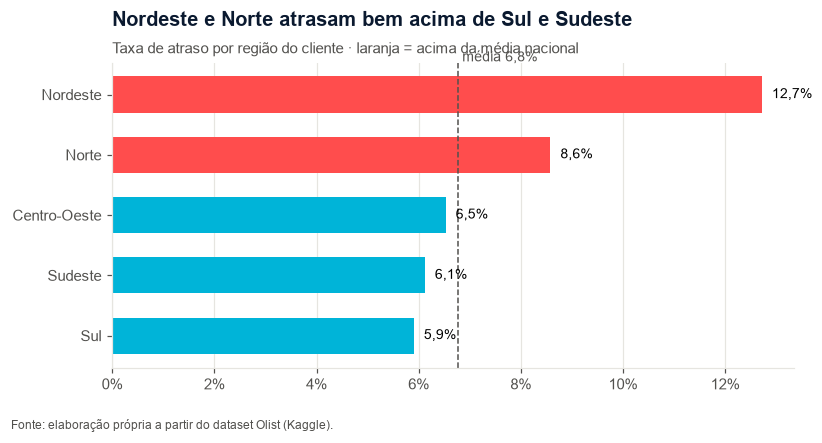

#### N6 · O atraso se concentra no Norte e no Nordeste

*Pergunta:* O atraso é igual no país inteiro?  
*Tipo:* análise núcleo · *Dimensões:* clientes, logística, geolocalização · *Desafios do enunciado:* Eficiência logística, Apoio à tomada de decisão · *Métricas na planilha:* M06

| | |
|---|---|
| **Fato** | A taxa de atraso é de 12,7% no Nordeste e 8,6% no Norte, contra 6,1% no Sudeste e 5,9% no Sul. Por estado, MA lidera (17,4%) entre os que têm 500 ou mais entregas. |
| **Leitura** | Os clientes mais distantes do eixo onde estão os vendedores sofrem mais atraso, embora o prazo prometido para eles já seja maior: em média 38 dias no Norte e 31 no Nordeste, contra 22 no Sudeste. Mesmo com essa folga, a promessa não acompanha a dificuldade real da rota. |
| **Cautela** | Estados pequenos têm poucas entregas e taxas instáveis. Região é um resumo: dentro dela há diferenças entre capital e interior que o dado por estado não mostra. |
| **E daí?** | Prazo prometido e acompanhamento podem ser calibrados por rota. Um agente de previsão de risco de atraso por região e vendedor é um uso direto deste achado. |


In [10]:
tab = (ent.groupby(["regiao", "customer_state"]).agg(entregues=("order_id", "count"), atrasados=("atrasado", "sum"),
                                                      prazo_medio=("prazo_dias", "mean")).reset_index()
          .rename(columns={"customer_state": "uf"}))
tab["atrasados"] = tab["atrasados"].astype(int)
tab["taxa_atraso"] = tab["atrasados"] / tab["entregues"]
tab = tab.sort_values("taxa_atraso", ascending=False, ignore_index=True)
reg = ent.groupby("regiao")["atrasado"].mean()
prom = ent.groupby("regiao")["prazo_prometido_dias"].mean()
book.add(id="M06", nome="Taxa de atraso por região e UF",
         definicao="Taxa de atraso dos pedidos entregues, por região e por estado do cliente.",
         formula="Por região (ou UF): pedidos atrasados ÷ pedidos entregues válidos.",
         tabelas="orders, customers", regras="R2, R4, R6", valor=reg["Nordeste"], unidade="%",
         esperados=[reg["Nordeste"], reg["Norte"], reg["Sudeste"], reg["Sul"], reg["Centro-Oeste"]],
         codigo='ent.groupby("regiao").atrasado.mean()',
         excel={r: f'AVERAGEIFS({{base:atrasado}},{{base:regiao}},"{r}")' for r in ["Nordeste", "Norte", "Sudeste", "Sul", "Centro-Oeste"]},
         tabela=tab, excel_linhas={"entregues": "COUNTIFS({base:customer_state},{cell:uf},{base:entregue_valido},1)",
                                   "atrasados": "COUNTIFS({base:customer_state},{cell:uf},{base:atrasado},1)",
                                   "prazo_medio": "AVERAGEIFS({base:prazo_dias},{base:customer_state},{cell:uf})",
                                   "taxa_atraso": "{cell:atrasados}/{cell:entregues}"})

fig, ax = plt.subplots(figsize=(8, 3.6))
rr = reg.sort_values()
media = ent["atrasado"].mean()
ax.barh(rr.index, rr.values, color=[viz.SERIES[1] if v > media else viz.SERIES[0] for v in rr.values], height=0.6)
ax.axvline(media, color=viz.TEXT_2, ls="--", lw=1)
ax.text(media, len(rr) - 0.45, f" média {fmt_pct(media)}", color=viz.TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for y, v in enumerate(rr.values):
    ax.text(v + 0.002, y, fmt_pct(v), va="center", fontsize=9)
viz.titles(ax, f"Nordeste e Norte atrasam bem acima de Sul e Sudeste",
           "Taxa de atraso por região do cliente · laranja = acima da média nacional")
viz.save(fig, "o3_n6_atraso_regiao")
plt.show()

fb.add(id="N6", tipo="núcleo", titulo="O atraso se concentra no Norte e no Nordeste",
       pergunta="O atraso é igual no país inteiro?",
       dimensoes=["clientes", "logística", "geolocalização"], desafios=["logistica", "decisao"], metricas=["M06"], figura="o3_n6_atraso_regiao",
       fato=f"A taxa de atraso é de {fmt_pct(reg['Nordeste'])} no Nordeste e {fmt_pct(reg['Norte'])} no Norte, contra {fmt_pct(reg['Sudeste'])} no Sudeste e "
            f"{fmt_pct(reg['Sul'])} no Sul. Por estado, {tab.query('entregues >= 500').iloc[0]['uf']} lidera ({fmt_pct(tab.query('entregues >= 500').iloc[0]['taxa_atraso'])}) entre os que têm 500 ou mais entregas.",
       leitura=f"Os clientes mais distantes do eixo onde estão os vendedores sofrem mais atraso, embora o prazo prometido para eles já seja maior: em média {br(prom['Norte'], 0)} dias no Norte e {br(prom['Nordeste'], 0)} no Nordeste, contra {br(prom['Sudeste'], 0)} no Sudeste. Mesmo com essa folga, a promessa não acompanha a dificuldade real da rota.",
       cautela="Estados pequenos têm poucas entregas e taxas instáveis. Região é um resumo: dentro dela há diferenças entre capital e interior que o dado por estado não mostra.",
       e_dai="Prazo prometido e acompanhamento podem ser calibrados por rota. Um agente de previsão de risco de atraso por região e vendedor é um uso direto deste achado.")

## Etapa 2 · Análises diferenciais
Estas análises vão além do óbvio e não estão no relatório de referência (CA2). Elas mostram **onde** e **quando** o problema nasce, que é o que um agente precisa saber para agir.

### D1 · Em que etapa do ciclo o atraso nasce
**Pergunta:** o pedido atrasado demora mais para ser aprovado, para ser postado pelo vendedor ou no transporte?

Ciclo do pedido: **compra → aprovação do pagamento → postagem pelo vendedor → entrega pela transportadora**.

M07 · Tempo médio por etapa: atrasados × no prazo: 27,89 dias


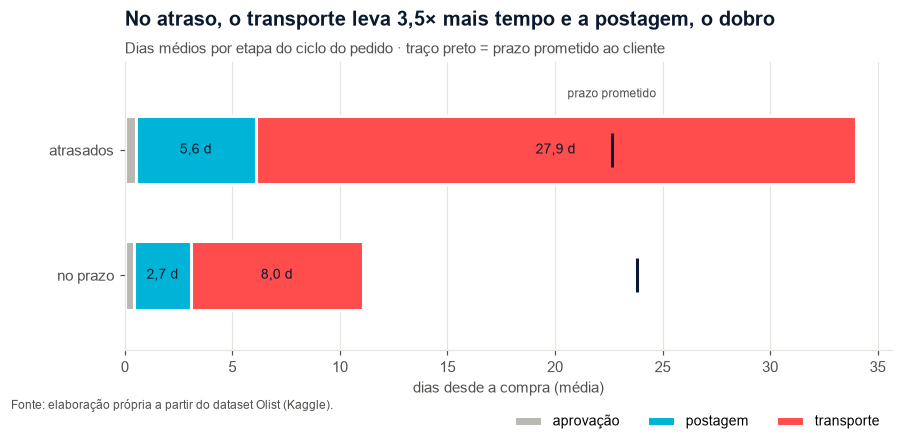

#### D1 · O atraso nasce sobretudo no transporte, e a postagem fora do prazo do vendedor multiplica o risco por 3,9

*Pergunta:* Em que etapa do ciclo o pedido atrasado perde tempo?  
*Tipo:* análise diferencial · *Dimensões:* pedidos, logística, vendedores · *Desafios do enunciado:* Eficiência logística, Eficiência operacional, Automação de processos · *Métricas na planilha:* M07

| | |
|---|---|
| **Fato** | Nos pedidos atrasados, o transporte leva em média 27,9 dias, contra 8,0 nos entregues no prazo. A postagem pelo vendedor leva 5,6 dias, contra 2,7. A aprovação do pagamento é igual nos dois grupos (menos de 1 dia). 9,0% dos pedidos foram postados depois do prazo-limite do vendedor; esses atrasam em 20,9% dos casos, contra 5,4% dos postados no prazo. |
| **Leitura** | O prazo prometido é parecido para os dois grupos (cerca de 23 dias), então o atraso não vem de uma promessa mais curta. Ele se forma no transporte e, em parte, na demora do vendedor para postar. A postagem fora do limite é um sinal de alerta que aparece dias antes de o atraso se concretizar. |
| **Cautela** | As datas de postagem e entrega são registros operacionais e podem ter erros (a regra R6 já tirou os casos impossíveis). O dado não diz qual transportadora fez a entrega. |
| **E daí?** | Há um gatilho objetivo para agir cedo: vendedor que passou do prazo de postagem. Um agente pode monitorar esse sinal, cobrar o vendedor e avisar o cliente antes que o atraso vire nota ruim. |


In [11]:
et = ent.groupby("atrasado")[["aprovacao_dias", "postagem_dias", "transporte_dias", "prazo_prometido_dias"]].mean()
fora = ent["postou_fora_limite"].mean()
atr_fora, atr_dentro = ent.loc[ent.postou_fora_limite == 1, "atrasado"].mean(), ent.loc[ent.postou_fora_limite == 0, "atrasado"].mean()
tab = et.T.rename(columns={0.0: "no_prazo", 1.0: "atrasado"}).rename_axis("etapa").reset_index()
tab["etapa"] = tab["etapa"].map({"aprovacao_dias": "aprovação", "postagem_dias": "postagem", "transporte_dias": "transporte", "prazo_prometido_dias": "prazo prometido"})
book.add(id="M07", nome="Tempo médio por etapa: atrasados × no prazo",
         definicao="Dias médios em cada etapa do ciclo (aprovação, postagem, transporte) e prazo prometido, para pedidos entregues no prazo e com atraso; postagem fora do prazo-limite.",
         formula="Média dos dias da etapa por grupo; postagens após o limite ÷ pedidos entregues; taxa de atraso com e sem postagem fora do limite.",
         tabelas="orders, order_items", regras="R4, R6", valor=et.loc[1, "transporte_dias"], unidade="dias",
         esperados=[et.loc[1, "transporte_dias"], et.loc[0, "transporte_dias"], et.loc[1, "postagem_dias"], et.loc[0, "postagem_dias"],
                    fora, atr_fora, atr_dentro],
         codigo='ent.groupby("atrasado")[["aprovacao_dias", "postagem_dias", "transporte_dias"]].mean()',
         excel={"transporte · atrasados": "AVERAGEIFS({base:transporte_dias},{base:atrasado},1)",
                "transporte · no prazo": "AVERAGEIFS({base:transporte_dias},{base:atrasado},0)",
                "postagem · atrasados": "AVERAGEIFS({base:postagem_dias},{base:atrasado},1)",
                "postagem · no prazo": "AVERAGEIFS({base:postagem_dias},{base:atrasado},0)",
                "% postou fora do limite": "AVERAGE({base:postou_fora_limite})",
                "atraso se postou fora": "AVERAGEIFS({base:atrasado},{base:postou_fora_limite},1)",
                "atraso se postou no limite": "AVERAGEIFS({base:atrasado},{base:postou_fora_limite},0)"},
         tabela=tab)

fig, ax = plt.subplots(figsize=(9, 3.4))
grupos = [("no prazo", 0.0), ("atrasados", 1.0)]
etapas_nome = [("aprovacao_dias", "aprovação"), ("postagem_dias", "postagem"), ("transporte_dias", "transporte")]
cores_et = [viz.MUTED, viz.SERIES[0], viz.SERIES[1]]
for y, (rot, g) in enumerate(grupos):
    left = 0
    for (col, nome), cor in zip(etapas_nome, cores_et):
        v = et.loc[g, col]
        ax.barh(y, v, left=left, color=cor, height=0.55, edgecolor=viz.SURFACE, linewidth=2, label=nome if y == 0 else None)
        if v > 1.5:
            ax.text(left + v / 2, y, f"{br(v)} d", ha="center", va="center", fontsize=9, color=viz.NAVY)
        left += v
    ax.plot(et.loc[g, "prazo_prometido_dias"], y, marker="|", markersize=22, color=viz.TEXT, mew=2)
ax.text(et.loc[1.0, "prazo_prometido_dias"], 1.42, "prazo prometido", ha="center", fontsize=8, color=viz.TEXT_2)
ax.set_yticks([0, 1], [g[0] for g in grupos])
ax.set_xlabel("dias desde a compra (média)")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, 1.7)
ax.legend(ncol=3, loc="upper right", fontsize=9, bbox_to_anchor=(1, -0.18))
viz.titles(ax, f"No atraso, o transporte leva {br(et.loc[1, 'transporte_dias'] / et.loc[0, 'transporte_dias'])}× mais tempo e a postagem, o dobro",
           "Dias médios por etapa do ciclo do pedido · traço preto = prazo prometido ao cliente")
viz.save(fig, "o3_d1_etapas_ciclo")
plt.show()

fb.add(id="D1", tipo="diferencial", titulo=f"O atraso nasce sobretudo no transporte, e a postagem fora do prazo do vendedor multiplica o risco por {br(atr_fora / atr_dentro)}",
       pergunta="Em que etapa do ciclo o pedido atrasado perde tempo?",
       dimensoes=["pedidos", "logística", "vendedores"], desafios=["logistica", "eficiencia", "automacao"], metricas=["M07"], figura="o3_d1_etapas_ciclo",
       fato=f"Nos pedidos atrasados, o transporte leva em média {br(et.loc[1, 'transporte_dias'])} dias, contra {br(et.loc[0, 'transporte_dias'])} nos entregues no prazo. "
            f"A postagem pelo vendedor leva {br(et.loc[1, 'postagem_dias'])} dias, contra {br(et.loc[0, 'postagem_dias'])}. A aprovação do pagamento é igual nos dois grupos (menos de 1 dia). "
            f"{fmt_pct(fora)} dos pedidos foram postados depois do prazo-limite do vendedor; esses atrasam em {fmt_pct(atr_fora)} dos casos, contra {fmt_pct(atr_dentro)} dos postados no prazo.",
       leitura="O prazo prometido é parecido para os dois grupos (cerca de 23 dias), então o atraso não vem de uma promessa mais curta. Ele se forma no transporte e, em parte, na demora do vendedor para postar. A postagem fora do limite é um sinal de alerta que aparece dias antes de o atraso se concretizar.",
       cautela="As datas de postagem e entrega são registros operacionais e podem ter erros (a regra R6 já tirou os casos impossíveis). O dado não diz qual transportadora fez a entrega.",
       e_dai="Há um gatilho objetivo para agir cedo: vendedor que passou do prazo de postagem. Um agente pode monitorar esse sinal, cobrar o vendedor e avisar o cliente antes que o atraso vire nota ruim.")

### D2 · Concentração por vendedor
**Pergunta:** o atraso está espalhado entre todos os vendedores ou concentrado em alguns?

M08 · Concentração do atraso por vendedor: 97 vendedores


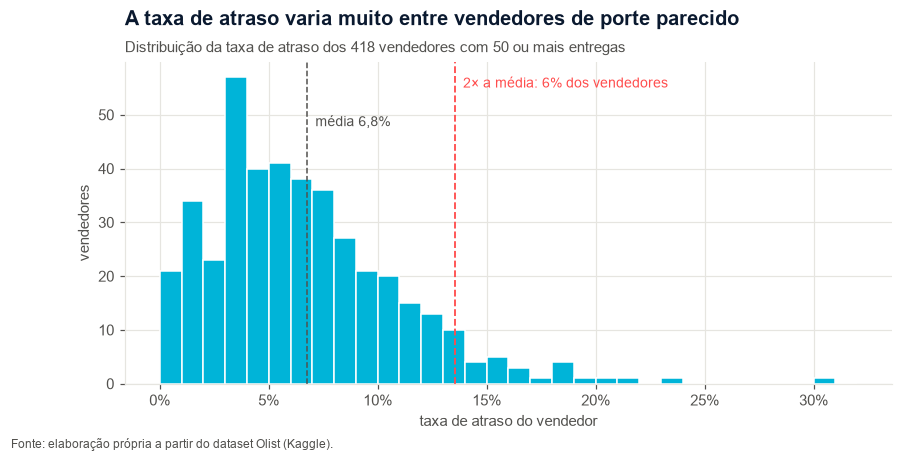

#### D2 · Os atrasos se concentram nos grandes vendedores, mas entre vendedores de porte parecido a taxa varia muito

*Pergunta:* O atraso está concentrado em alguns vendedores?  
*Tipo:* análise diferencial · *Dimensões:* vendedores, logística · *Desafios do enunciado:* Apoio à tomada de decisão, Eficiência logística, Escalabilidade da operação · *Métricas na planilha:* M08

| | |
|---|---|
| **Fato** | 97 dos 2.957 vendedores com entregas (3,3%) respondem por metade dos pedidos atrasados. Metade dos pedidos vem de 127 vendedores, então a concentração dos atrasos acompanha a das vendas. Entre os 418 vendedores com 50 ou mais entregas, a taxa de atraso vai de 3,6% (quartil inferior) a 8,9% (quartil superior), e 6% deles atrasam o dobro da média ou mais. |
| **Leitura** | Os grandes vendedores pesam mais nos atrasos porque vendem mais, mas, entre vendedores de porte parecido, há os que entregam bem e os que atrasam com frequência. Isso é compatível com diferenças de processo de cada vendedor. |
| **Cautela** | A taxa de um vendedor mistura sua própria agilidade com a região dos clientes e a transportadora usada. O vendedor do pedido é o do item de maior preço; pedidos com vários vendedores são poucos. |
| **E daí?** | Acompanhar os vendedores pelo desempenho de entrega permite agir onde o problema se repete. Um agente pode gerar alertas e recomendações para o time que cuida dos lojistas, com foco em poucos vendedores e grande efeito. |


In [12]:
vs = (ent.groupby("seller_id").agg(entregas=("order_id", "count"), atrasados=("atrasado", "sum")).reset_index()
         .sort_values("atrasados", ascending=False, ignore_index=True))
vs["atrasados"] = vs["atrasados"].astype(int)
vs["pct_acum_atrasos"] = (vs["atrasados"].cumsum() / vs["atrasados"].sum()).round(6)
vs["taxa_atraso"] = vs["atrasados"] / vs["entregas"]
vp = vs.sort_values("entregas", ascending=False)
vend_50_atr = int((vs["pct_acum_atrasos"] <= 0.5).sum())
vend_50_ped = int((vp["entregas"].cumsum() / vp["entregas"].sum() <= 0.5).sum())
grandes = vs[vs["entregas"] >= 50]
media_v = ent["atrasado"].mean()
dobro = (grandes["taxa_atraso"] >= 2 * media_v).mean()
q1, q3 = grandes["taxa_atraso"].quantile([0.25, 0.75])
book.add(id="M08", nome="Concentração do atraso por vendedor",
         definicao="Quantos vendedores concentram metade dos atrasos e, entre os vendedores com 50 ou mais entregas, que parte atrasa o dobro da média.",
         formula="Vendedores (ordenados por atrasos) até 50% dos atrasos acumulados; vendedores com 50+ entregas e taxa ≥ 2× a média ÷ vendedores com 50+ entregas.",
         tabelas="order_items, sellers, orders", regras="R1, R4, R6", valor=vend_50_atr, unidade="vendedores",
         esperados=[vend_50_atr, len(vs), dobro],
         codigo='(vs.pct_acum_atrasos <= 0.5).sum()',
         excel={"vendedores com 50% dos atrasos": 'COUNTIF({tab:pct_acum_atrasos},"<=0.5")',
                "vendedores com entrega": "COUNTA({tab:seller_id})",
                "% (50+ entregas) com 2× a média": f'COUNTIFS({{tab:entregas}},">=50",{{tab:taxa_atraso}},">={2 * media_v:.10f}")/COUNTIF({{tab:entregas}},">=50")'},
         tabela=vs)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(grandes["taxa_atraso"], bins=np.arange(0, grandes["taxa_atraso"].max() + 0.02, 0.01), color=viz.SERIES[0], edgecolor=viz.SURFACE)
ax.axvline(media_v, color=viz.TEXT_2, ls="--", lw=1)
ax.axvline(2 * media_v, color=viz.SERIES[1], ls="--", lw=1.2)
ax.text(2 * media_v, ax.get_ylim()[1] * 0.92, f"  2× a média: {fmt_pct(dobro, 0)} dos vendedores", color=viz.SERIES[1], fontsize=9)
ax.text(media_v, ax.get_ylim()[1] * 0.8, f"  média {fmt_pct(media_v)}", color=viz.TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("taxa de atraso do vendedor"); ax.set_ylabel("vendedores")
viz.titles(ax, "A taxa de atraso varia muito entre vendedores de porte parecido",
           f"Distribuição da taxa de atraso dos {fmt_int(len(grandes))} vendedores com 50 ou mais entregas")
viz.save(fig, "o3_d2_vendedores")
plt.show()

fb.add(id="D2", tipo="diferencial", titulo="Os atrasos se concentram nos grandes vendedores, mas entre vendedores de porte parecido a taxa varia muito",
       pergunta="O atraso está concentrado em alguns vendedores?",
       dimensoes=["vendedores", "logística"], desafios=["decisao", "logistica", "escala"], metricas=["M08"], figura="o3_d2_vendedores",
       fato=f"{fmt_int(vend_50_atr)} dos {fmt_int(len(vs))} vendedores com entregas ({fmt_pct(vend_50_atr / len(vs))}) respondem por metade dos pedidos atrasados. "
            f"Metade dos pedidos vem de {fmt_int(vend_50_ped)} vendedores, então a concentração dos atrasos acompanha a das vendas. "
            f"Entre os {fmt_int(len(grandes))} vendedores com 50 ou mais entregas, a taxa de atraso vai de {fmt_pct(q1)} (quartil inferior) a {fmt_pct(q3)} (quartil superior), "
            f"e {fmt_pct(dobro, 0)} deles atrasam o dobro da média ou mais.",
       leitura="Os grandes vendedores pesam mais nos atrasos porque vendem mais, mas, entre vendedores de porte parecido, há os que entregam bem e os que atrasam com frequência. Isso é compatível com diferenças de processo de cada vendedor.",
       cautela="A taxa de um vendedor mistura sua própria agilidade com a região dos clientes e a transportadora usada. O vendedor do pedido é o do item de maior preço; pedidos com vários vendedores são poucos.",
       e_dai="Acompanhar os vendedores pelo desempenho de entrega permite agir onde o problema se repete. Um agente pode gerar alertas e recomendações para o time que cuida dos lojistas, com foco em poucos vendedores e grande efeito.")

### D3 · Categoria e peso do produto
**Pergunta:** algumas categorias e produtos mais pesados atrasam mais e são pior avaliados?

M09 · Atraso e nota por peso e categoria: 8,9%


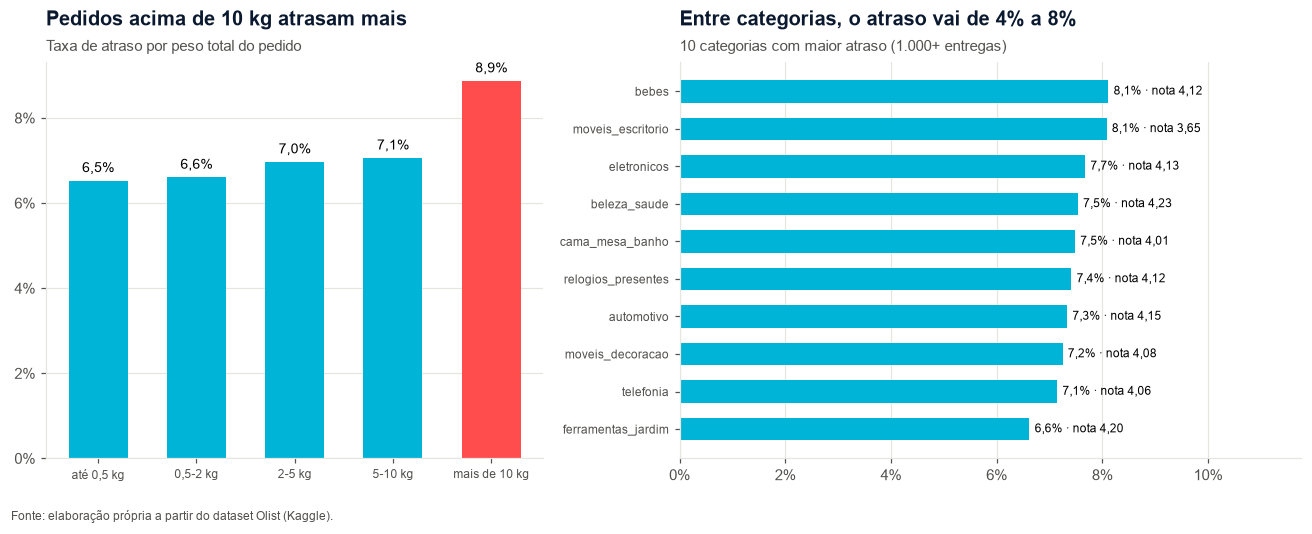

#### D3 · Produtos pesados atrasam mais e são pior avaliados, e o atraso quase dobra entre a melhor e a pior categoria

*Pergunta:* Categoria e peso do produto estão associados a atraso e nota?  
*Tipo:* análise diferencial · *Dimensões:* produtos, logística, avaliações · *Desafios do enunciado:* Eficiência logística, Experiência do cliente · *Métricas na planilha:* M09

| | |
|---|---|
| **Fato** | Pedidos com mais de 10 kg atrasam em 8,9% dos casos, contra 6,5% nos de até 0,5 kg, e têm nota média 3,90, contra 4,19. Entre as categorias com 1.000 ou mais entregas, a taxa de atraso vai de 4,2% (malas_acessorios) a 8,1% (bebes). |
| **Leitura** | Peso e categoria aparecem associados ao atraso e à nota. Itens volumosos exigem transporte diferente e parecem sofrer mais na rota. Móveis de escritório combinam atraso acima da média com a pior nota entre as grandes categorias (3,65). |
| **Cautela** | Peso e categoria andam juntos (móveis são pesados) e com a região do cliente. O peso vem do cadastro do produto e falta em poucos casos (regra R5). |
| **E daí?** | Pedidos pesados merecem prazo prometido mais realista e acompanhamento mais próximo. O peso é uma variável útil para um agente que estima o risco de atraso no momento da compra. |


In [13]:
cat = (ent.groupby("categoria").agg(entregas=("order_id", "count"), atrasados=("atrasado", "sum"),
                                    nota_media=("review_score", "mean")).reset_index().query("entregas >= 1000"))
cat["atrasados"] = cat["atrasados"].astype(int)
cat["taxa_atraso"] = cat["atrasados"] / cat["entregas"]
cat = cat.sort_values("taxa_atraso", ascending=False, ignore_index=True)
pesos = (ent.groupby("faixa_peso").agg(entregas=("order_id", "count"), taxa_atraso=("atrasado", "mean"),
                                       nota_media=("review_score", "mean"), prazo_medio=("prazo_dias", "mean")).reset_index())
pp = pesos.set_index("faixa_peso")
book.add(id="M09", nome="Atraso e nota por peso e categoria",
         definicao="Taxa de atraso, nota média e prazo por faixa de peso do pedido; a aba traz também as categorias com 1.000 ou mais entregas.",
         formula="Por faixa de peso: pedidos atrasados ÷ entregues; média das notas; média do prazo.",
         tabelas="products, order_items, orders, order_reviews", regras="R1, R4, R5, R6", valor=pp.loc["e. mais de 10 kg", "taxa_atraso"], unidade="%",
         esperados=[pp.loc["e. mais de 10 kg", "taxa_atraso"], pp.loc["a. até 0,5 kg", "taxa_atraso"],
                    pp.loc["e. mais de 10 kg", "nota_media"], pp.loc["a. até 0,5 kg", "nota_media"]],
         codigo='ent.groupby("faixa_peso")[["atrasado", "review_score"]].mean()',
         excel={"atraso · mais de 10 kg": 'AVERAGEIFS({base:atrasado},{base:faixa_peso},"e. mais de 10 kg")',
                "atraso · até 0,5 kg": 'AVERAGEIFS({base:atrasado},{base:faixa_peso},"a. até 0,5 kg")',
                "nota · mais de 10 kg": 'AVERAGEIFS({base:review_score},{base:faixa_peso},"e. mais de 10 kg",{base:entregue_valido},1)',
                "nota · até 0,5 kg": 'AVERAGEIFS({base:review_score},{base:faixa_peso},"a. até 0,5 kg",{base:entregue_valido},1)'},
         tabela=cat, excel_linhas={"entregas": "COUNTIFS({base:categoria},{cell:categoria},{base:entregue_valido},1)",
                                   "atrasados": "COUNTIFS({base:categoria},{cell:categoria},{base:atrasado},1)",
                                   "taxa_atraso": "{cell:atrasados}/{cell:entregas}"})

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axs[0]
ax.bar(pesos["faixa_peso"].str[3:], pesos["taxa_atraso"], color=[viz.SERIES[0]] * 4 + [viz.SERIES[1]], width=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=8)
for x, v in enumerate(pesos["taxa_atraso"]):
    ax.text(x, v + 0.002, fmt_pct(v), ha="center", fontsize=9)
viz.titles(ax, "Pedidos acima de 10 kg atrasam mais", "Taxa de atraso por peso total do pedido")
ax = axs[1]
cc = cat.sort_values("taxa_atraso").tail(10)
ax.barh(cc["categoria"], cc["taxa_atraso"], color=viz.SERIES[0], height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
for y, (v, n) in enumerate(zip(cc["taxa_atraso"], cc["nota_media"])):
    ax.text(v + 0.001, y, f"{fmt_pct(v)} · nota {br(n, 2)}", va="center", fontsize=8)
ax.set_xlim(0, cc["taxa_atraso"].max() * 1.45)
viz.titles(ax, f"Entre categorias, o atraso vai de {fmt_pct(cat.taxa_atraso.min(), 0)} a {fmt_pct(cat.taxa_atraso.max(), 0)}", "10 categorias com maior atraso (1.000+ entregas)")
fig.tight_layout()
viz.save(fig, "o3_d3_peso_categoria")
plt.show()

fb.add(id="D3", tipo="diferencial", titulo="Produtos pesados atrasam mais e são pior avaliados, e o atraso quase dobra entre a melhor e a pior categoria",
       pergunta="Categoria e peso do produto estão associados a atraso e nota?",
       dimensoes=["produtos", "logística", "avaliações"], desafios=["logistica", "cliente"], metricas=["M09"], figura="o3_d3_peso_categoria",
       fato=f"Pedidos com mais de 10 kg atrasam em {fmt_pct(pp.loc['e. mais de 10 kg', 'taxa_atraso'])} dos casos, contra {fmt_pct(pp.loc['a. até 0,5 kg', 'taxa_atraso'])} nos de até 0,5 kg, "
            f"e têm nota média {br(pp.loc['e. mais de 10 kg', 'nota_media'], 2)}, contra {br(pp.loc['a. até 0,5 kg', 'nota_media'], 2)}. "
            f"Entre as categorias com 1.000 ou mais entregas, a taxa de atraso vai de {fmt_pct(cat.taxa_atraso.min())} ({cat.iloc[-1]['categoria']}) a {fmt_pct(cat.taxa_atraso.max())} ({cat.iloc[0]['categoria']}).",
       leitura=f"Peso e categoria aparecem associados ao atraso e à nota. Itens volumosos exigem transporte diferente e parecem sofrer mais na rota. Móveis de escritório combinam atraso acima da média com a pior nota entre as grandes categorias ({br(cat.set_index('categoria').loc['moveis_escritorio', 'nota_media'], 2)}).",
       cautela="Peso e categoria andam juntos (móveis são pesados) e com a região do cliente. O peso vem do cadastro do produto e falta em poucos casos (regra R5).",
       e_dai="Pedidos pesados merecem prazo prometido mais realista e acompanhamento mais próximo. O peso é uma variável útil para um agente que estima o risco de atraso no momento da compra.")

### D4 · Frete, valor e forma de pagamento × nota
**Pergunta:** o cliente avalia pior quando o frete pesa mais no valor do pedido? A forma de pagamento faz diferença?

In [14]:
fr = ent.groupby("faixa_frete").agg(entregas=("order_id", "count"), frete_pct_medio=("frete_pct", "mean"),
                                     nota_media=("review_score", "mean"), taxa_atraso=("atrasado", "mean")).reset_index()
pg = a.groupby("pagamento").agg(pedidos=("order_id", "count"), nota_media=("review_score", "mean"),
                                parcelas_media=("parcelas", "mean")).reset_index().query("pedidos >= 100")
fq = fr.set_index("faixa_frete")
cartao_parc = (a.loc[a.pagamento == "credit_card", "parcelas"] > 1).mean()
book.add(id="M10", nome="Nota por peso do frete e forma de pagamento",
         definicao="Nota média dos pedidos entregues por quintil do peso do frete no valor (frete ÷ preço + frete); a aba traz a nota por forma de pagamento.",
         formula="Por quintil de frete: média das notas dos pedidos entregues; diferença entre o quintil de maior e o de menor frete.",
         tabelas="order_items, payments, order_reviews", regras="R3, R8", valor=fq.loc["q1 (menor frete)", "nota_media"] - fq.loc["q5 (maior frete)", "nota_media"], unidade="pontos",
         esperados=[fq.loc["q1 (menor frete)", "nota_media"] - fq.loc["q5 (maior frete)", "nota_media"], fq.loc["q1 (menor frete)", "nota_media"],
                    fq.loc["q5 (maior frete)", "nota_media"], cartao_parc],
         codigo='ent.groupby("faixa_frete").review_score.mean()',
         excel={"diferença q1 − q5": 'AVERAGEIFS({base:review_score},{base:faixa_frete},"q1 (menor frete)",{base:entregue_valido},1)-AVERAGEIFS({base:review_score},{base:faixa_frete},"q5 (maior frete)",{base:entregue_valido},1)',
                "nota · menor frete": 'AVERAGEIFS({base:review_score},{base:faixa_frete},"q1 (menor frete)",{base:entregue_valido},1)',
                "nota · maior frete": 'AVERAGEIFS({base:review_score},{base:faixa_frete},"q5 (maior frete)",{base:entregue_valido},1)',
                "cartão parcelado": 'COUNTIFS({base:pagamento},"credit_card",{base:parcelas},">1")/COUNTIF({base:pagamento},"credit_card")'},
         tabela=pg)
display(fr)

fb.add(id="D4", tipo="diferencial", titulo="O peso do frete e a forma de pagamento quase não mudam a nota; o que pesa é o prazo",
       pergunta="Frete caro ou forma de pagamento estão associados a notas piores?",
       dimensoes=["pagamentos", "produtos", "avaliações"], desafios=["cliente", "decisao"], metricas=["M10"],
       fato=f"A nota média vai de {br(fq.loc['q1 (menor frete)', 'nota_media'], 2)} nos pedidos em que o frete pesa menos para {br(fq.loc['q5 (maior frete)', 'nota_media'], 2)} nos que pesa mais, "
            f"uma diferença de {br(fq.loc['q1 (menor frete)', 'nota_media'] - fq.loc['q5 (maior frete)', 'nota_media'], 2)} ponto. "
            f"Entre as formas de pagamento, a nota média fica entre {br(pg.nota_media.min(), 2)} e {br(pg.nota_media.max(), 2)}. {fmt_pct(cartao_parc, 0)} das compras no cartão são parceladas.",
       leitura=f"Comparada à queda de cerca de 2 pontos associada ao atraso (OLIST-2, I09), a diferença ligada ao frete é pequena. O cliente parece aceitar o preço do frete combinado na compra; o que ele não aceita é o prazo descumprido.",
       cautela="O dado não traz o frete de concorrentes nem o abandono de carrinho: clientes que desistiram da compra pelo valor do frete não aparecem. A análise vale só para quem comprou.",
       e_dai="Para a satisfação, cumprir o prazo vale mais do que baratear o frete. Esse achado ajuda a priorizar: agentes ligados a prazo e comunicação vêm antes de agentes de preço de frete.")

M10 · Nota por peso do frete e forma de pagamento: 0,1 pontos


,faixa_frete,entregas,frete_pct_medio,nota_media,taxa_atraso
0,q1 (menor frete),19202,0.068,4.205,0.068
1,q2,19305,0.129,4.177,0.066
2,q3,19297,0.184,4.164,0.065
3,q4,19336,0.254,4.126,0.070
4,q5 (maior frete),19307,0.409,4.109,0.070


#### D4 · O peso do frete e a forma de pagamento quase não mudam a nota; o que pesa é o prazo

*Pergunta:* Frete caro ou forma de pagamento estão associados a notas piores?  
*Tipo:* análise diferencial · *Dimensões:* pagamentos, produtos, avaliações · *Desafios do enunciado:* Experiência do cliente, Apoio à tomada de decisão · *Métricas na planilha:* M10

| | |
|---|---|
| **Fato** | A nota média vai de 4,20 nos pedidos em que o frete pesa menos para 4,11 nos que pesa mais, uma diferença de 0,10 ponto. Entre as formas de pagamento, a nota média fica entre 4,00 e 4,17. 68% das compras no cartão são parceladas. |
| **Leitura** | Comparada à queda de cerca de 2 pontos associada ao atraso (OLIST-2, I09), a diferença ligada ao frete é pequena. O cliente parece aceitar o preço do frete combinado na compra; o que ele não aceita é o prazo descumprido. |
| **Cautela** | O dado não traz o frete de concorrentes nem o abandono de carrinho: clientes que desistiram da compra pelo valor do frete não aparecem. A análise vale só para quem comprou. |
| **E daí?** | Para a satisfação, cumprir o prazo vale mais do que baratear o frete. Esse achado ajuda a priorizar: agentes ligados a prazo e comunicação vêm antes de agentes de preço de frete. |


### D5 · Sazonalidade: picos de demanda
**Pergunta:** o atraso e a nota mudam ao longo do ano, em datas como a Black Friday?

M11 · Taxa de atraso e nota por mês: 19,0%


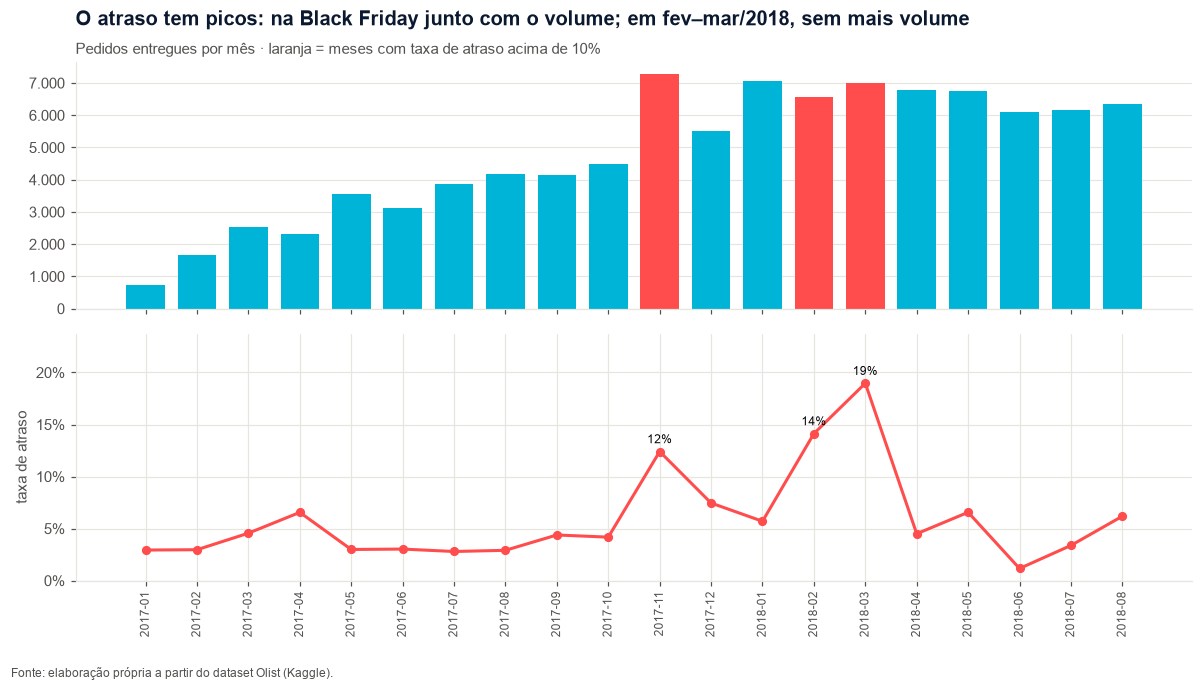

#### D5 · O atraso tem picos em poucos meses: na Black Friday de 2017 junto com o volume, e em fevereiro–março de 2018 sem aumento de volume

*Pergunta:* O atraso muda ao longo do ano?  
*Tipo:* análise diferencial · *Dimensões:* pedidos, logística, avaliações · *Desafios do enunciado:* Escalabilidade da operação, Eficiência logística, Apoio à tomada de decisão · *Métricas na planilha:* M11

| | |
|---|---|
| **Fato** | A taxa de atraso mensal fica perto de 4% na maior parte dos meses, mas chega a 12,4% em novembro de 2017 (Black Friday), 14,1% em fevereiro e 19,0% em março de 2018. Nesses meses a nota média cai para 3,99, 3,88 e 3,81. |
| **Leitura** | Na Black Friday, o salto de atraso coincide com o maior volume do período (7.288 entregas). Em fevereiro e março de 2018 o volume foi parecido com o de janeiro (7.069), que teve atraso de 5,7%; esse pico é compatível com fatores externos, como greves ou problemas nas transportadoras, que o dado não registra. Nos dois casos, a nota acompanha a pontualidade. |
| **Cautela** | São poucos meses de pico, e não sabemos o que aconteceu fora da Olist nesses períodos. A série tem menos de dois anos completos, então não dá para afirmar um padrão anual. |
| **E daí?** | Planejar a capacidade antes das datas de pico e ajustar o prazo prometido nesses períodos protege a nota. Um agente de apoio à decisão pode simular o volume esperado e sugerir prazos e reforços com antecedência. |


In [15]:
BORDA = ["2016-09", "2016-10", "2016-12", "2018-09", "2018-10"]
mes = (ent[~ent["ano_mes"].isin(BORDA)].groupby("ano_mes").agg(entregas=("order_id", "count"), atrasados=("atrasado", "sum"),
                                                              nota_media=("review_score", "mean")).reset_index())
mes["atrasados"] = mes["atrasados"].astype(int)
mes["taxa_atraso"] = mes["atrasados"] / mes["entregas"]
mes = mes[mes["ano_mes"] >= "2017-01"].reset_index(drop=True)
mm = mes.set_index("ano_mes")
base_mes = mes[~mes["ano_mes"].isin(["2017-11", "2017-12", "2018-02", "2018-03"])]["taxa_atraso"].median()
book.add(id="M11", nome="Taxa de atraso e nota por mês",
         definicao="Taxa de atraso e nota média dos pedidos entregues, por mês de compra (jan/2017 a ago/2018, sem meses de borda).",
         formula="Por mês: pedidos atrasados ÷ pedidos entregues válidos; média das notas.",
         tabelas="orders, order_reviews", regras="R3, R4, R6", valor=mm.loc["2018-03", "taxa_atraso"], unidade="%",
         esperados=[mm.loc["2018-03", "taxa_atraso"], mm.loc["2018-02", "taxa_atraso"], mm.loc["2017-11", "taxa_atraso"]],
         codigo='ent.groupby("ano_mes").atrasado.mean()',
         excel={"mar/2018": 'AVERAGEIFS({base:atrasado},{base:ano_mes},"2018-03")',
                "fev/2018": 'AVERAGEIFS({base:atrasado},{base:ano_mes},"2018-02")',
                "nov/2017": 'AVERAGEIFS({base:atrasado},{base:ano_mes},"2017-11")'},
         tabela=mes, excel_linhas={"entregas": "COUNTIFS({base:ano_mes},{cell:ano_mes},{base:entregue_valido},1)",
                                   "atrasados": "COUNTIFS({base:ano_mes},{cell:ano_mes},{base:atrasado},1)",
                                   "nota_media": "AVERAGEIFS({base:review_score},{base:ano_mes},{cell:ano_mes},{base:entregue_valido},1)",
                                   "taxa_atraso": "{cell:atrasados}/{cell:entregas}"})

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
x = mes["ano_mes"]
pico = mes["ano_mes"].isin(["2017-11", "2018-02", "2018-03"])
axs[0].bar(x, mes["entregas"], color=[viz.SERIES[1] if p else viz.SERIES[0] for p in pico], width=0.75)
axs[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v))); axs[0].grid(axis="x", visible=False)
viz.titles(axs[0], "O atraso tem picos: na Black Friday junto com o volume; em fev–mar/2018, sem mais volume",
           "Pedidos entregues por mês · laranja = meses com taxa de atraso acima de 10%")
axs[1].plot(x, mes["taxa_atraso"], color=viz.SERIES[1], lw=2, marker="o", ms=5)
axs[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axs[1].set_ylabel("taxa de atraso")
ax2_txt = [axs[1].text(i, v + 0.008, fmt_pct(v, 0), ha="center", fontsize=8) for i, (v, p) in enumerate(zip(mes["taxa_atraso"], pico)) if p]
axs[1].tick_params(axis="x", rotation=90, labelsize=8)
axs[1].set_ylim(0, mes["taxa_atraso"].max() * 1.25)
fig.tight_layout()
viz.save(fig, "o3_d5_sazonalidade")
plt.show()

fb.add(id="D5", tipo="diferencial", titulo="O atraso tem picos em poucos meses: na Black Friday de 2017 junto com o volume, e em fevereiro–março de 2018 sem aumento de volume",
       pergunta="O atraso muda ao longo do ano?",
       dimensoes=["pedidos", "logística", "avaliações"], desafios=["escala", "logistica", "decisao"], metricas=["M11"], figura="o3_d5_sazonalidade",
       fato=f"A taxa de atraso mensal fica perto de {fmt_pct(base_mes, 0)} na maior parte dos meses, mas chega a {fmt_pct(mm.loc['2017-11', 'taxa_atraso'])} em novembro de 2017 (Black Friday), "
            f"{fmt_pct(mm.loc['2018-02', 'taxa_atraso'])} em fevereiro e {fmt_pct(mm.loc['2018-03', 'taxa_atraso'])} em março de 2018. "
            f"Nesses meses a nota média cai para {br(mm.loc['2017-11', 'nota_media'], 2)}, {br(mm.loc['2018-02', 'nota_media'], 2)} e {br(mm.loc['2018-03', 'nota_media'], 2)}.",
       leitura=f"Na Black Friday, o salto de atraso coincide com o maior volume do período ({fmt_int(mm.loc['2017-11', 'entregas'])} entregas). Em fevereiro e março de 2018 o volume foi parecido com o de janeiro ({fmt_int(mm.loc['2018-01', 'entregas'])}), que teve atraso de {fmt_pct(mm.loc['2018-01', 'taxa_atraso'])}; esse pico é compatível com fatores externos, como greves ou problemas nas transportadoras, que o dado não registra. Nos dois casos, a nota acompanha a pontualidade.",
       cautela="São poucos meses de pico, e não sabemos o que aconteceu fora da Olist nesses períodos. A série tem menos de dois anos completos, então não dá para afirmar um padrão anual.",
       e_dai="Planejar a capacidade antes das datas de pico e ajustar o prazo prometido nesses períodos protege a nota. Um agente de apoio à decisão pode simular o volume esperado e sugerir prazos e reforços com antecedência.")

### D6 · Distância e rota entre vendedor e cliente
**Pergunta:** quanto mais longe o vendedor está do cliente, maior o atraso? Vender dentro do próprio estado ajuda?

A distância é calculada em linha reta entre os CEPs do vendedor e do cliente, usando a geolocalização com 1 ponto por CEP (regra R7).

M12 · Atraso por distância e por rota (mesma UF × outra UF): 8,0%


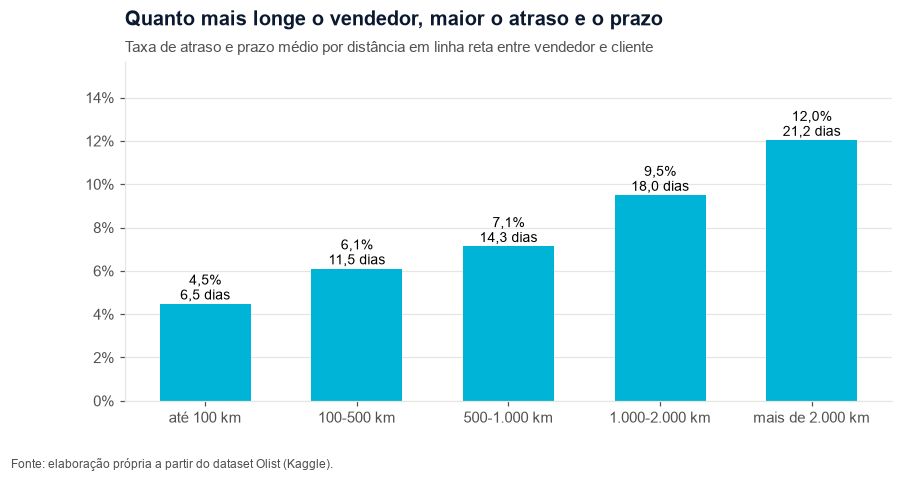

#### D6 · A distância entre vendedor e cliente acompanha o atraso, e a maioria das vendas cruza estados

*Pergunta:* A distância e a rota entre vendedor e cliente estão associadas ao atraso?  
*Tipo:* análise diferencial · *Dimensões:* geolocalização, vendedores, clientes, logística · *Desafios do enunciado:* Eficiência logística, Apoio à tomada de decisão, Escalabilidade da operação · *Métricas na planilha:* M12

| | |
|---|---|
| **Fato** | A taxa de atraso sobe de 4,5% (até 100 km) para 12,0% (mais de 2.000 km). Quando vendedor e cliente estão em estados diferentes, o atraso é de 8,0% e o prazo médio de 15,2 dias; no mesmo estado, 4,5% e 7,9 dias. 64% das entregas cruzam estados. |
| **Leitura** | A rota acompanha boa parte da diferença regional vista em N6: os vendedores estão concentrados no Sudeste, e o cliente distante depende de transporte longo, que é onde o atraso nasce (D1). |
| **Cautela** | A distância em linha reta é uma aproximação da rota real. CEPs sem coordenada (menos de 1%) ficam de fora. |
| **E daí?** | Aproximar a oferta do cliente, com vendedores ou estoques em outras regiões, e calibrar o prazo pela distância são alavancas estratégicas. A distância também é uma variável simples para o agente que estima o risco de atraso. |


In [16]:
dist = (ent.groupby("faixa_distancia").agg(entregas=("order_id", "count"), atrasados=("atrasado", "sum"),
                                           prazo_medio=("prazo_dias", "mean"), nota_media=("review_score", "mean")).reset_index())
dist["atrasados"] = dist["atrasados"].astype(int)
dist["taxa_atraso"] = dist["atrasados"] / dist["entregas"]
uf_mesma, uf_outra = ent.loc[ent.mesma_uf == 1, "atrasado"].mean(), ent.loc[ent.mesma_uf == 0, "atrasado"].mean()
pr_mesma, pr_outra = ent.loc[ent.mesma_uf == 1, "prazo_dias"].mean(), ent.loc[ent.mesma_uf == 0, "prazo_dias"].mean()
pct_inter = (ent["mesma_uf"] == 0).mean()
book.add(id="M12", nome="Atraso por distância e por rota (mesma UF × outra UF)",
         definicao="Taxa de atraso e prazo dos pedidos entregues conforme a distância entre vendedor e cliente e conforme estejam no mesmo estado.",
         formula="Por faixa de distância (ou rota): pedidos atrasados ÷ entregues válidos; média do prazo.",
         tabelas="orders, customers, sellers, geolocation", regras="R4, R6, R7", valor=uf_outra, unidade="%",
         esperados=[uf_outra, uf_mesma, pr_outra, pr_mesma, pct_inter],
         codigo='ent.groupby("mesma_uf")[["atrasado", "prazo_dias"]].mean()',
         excel={"atraso · outra UF": "AVERAGEIFS({base:atrasado},{base:mesma_uf},0)",
                "atraso · mesma UF": "AVERAGEIFS({base:atrasado},{base:mesma_uf},1)",
                "prazo · outra UF": "AVERAGEIFS({base:prazo_dias},{base:mesma_uf},0)",
                "prazo · mesma UF": "AVERAGEIFS({base:prazo_dias},{base:mesma_uf},1)",
                "% interestadual": "COUNTIFS({base:mesma_uf},0,{base:entregue_valido},1)/COUNTIFS({base:mesma_uf},\">=0\",{base:entregue_valido},1)"},
         tabela=dist, excel_linhas={"entregas": "COUNTIFS({base:faixa_distancia},{cell:faixa_distancia},{base:entregue_valido},1)",
                                    "atrasados": "COUNTIFS({base:faixa_distancia},{cell:faixa_distancia},{base:atrasado},1)",
                                    "prazo_medio": "AVERAGEIFS({base:prazo_dias},{base:faixa_distancia},{cell:faixa_distancia})",
                                    "taxa_atraso": "{cell:atrasados}/{cell:entregas}"})

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dist["faixa_distancia"].str[3:], dist["taxa_atraso"], color=viz.SERIES[0], width=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.grid(axis="x", visible=False)
for xx, (v, p) in enumerate(zip(dist["taxa_atraso"], dist["prazo_medio"])):
    ax.text(xx, v + 0.002, f"{fmt_pct(v)}\n{br(p)} dias", ha="center", fontsize=9)
ax.set_ylim(0, dist["taxa_atraso"].max() * 1.3)
viz.titles(ax, f"Quanto mais longe o vendedor, maior o atraso e o prazo",
           "Taxa de atraso e prazo médio por distância em linha reta entre vendedor e cliente")
viz.save(fig, "o3_d6_distancia")
plt.show()

fb.add(id="D6", tipo="diferencial", titulo="A distância entre vendedor e cliente acompanha o atraso, e a maioria das vendas cruza estados",
       pergunta="A distância e a rota entre vendedor e cliente estão associadas ao atraso?",
       dimensoes=["geolocalização", "vendedores", "clientes", "logística"], desafios=["logistica", "decisao", "escala"], metricas=["M12"], figura="o3_d6_distancia",
       fato=f"A taxa de atraso sobe de {fmt_pct(dist.taxa_atraso.iloc[0])} (até 100 km) para {fmt_pct(dist.taxa_atraso.iloc[-1])} (mais de 2.000 km). "
            f"Quando vendedor e cliente estão em estados diferentes, o atraso é de {fmt_pct(uf_outra)} e o prazo médio de {br(pr_outra)} dias; "
            f"no mesmo estado, {fmt_pct(uf_mesma)} e {br(pr_mesma)} dias. {fmt_pct(pct_inter, 0)} das entregas cruzam estados.",
       leitura="A rota acompanha boa parte da diferença regional vista em N6: os vendedores estão concentrados no Sudeste, e o cliente distante depende de transporte longo, que é onde o atraso nasce (D1).",
       cautela="A distância em linha reta é uma aproximação da rota real. CEPs sem coordenada (menos de 1%) ficam de fora.",
       e_dai="Aproximar a oferta do cliente, com vendedores ou estoques em outras regiões, e calibrar o prazo pela distância são alavancas estratégicas. A distância também é uma variável simples para o agente que estima o risco de atraso.")

## Etapa 3 · Achados-chave
Dos 12 achados, estes 6 são os que mais pesam na escolha dos agentes. Eles estão em ordem de relevância: primeiro o que afeta mais clientes e tem sinal mais forte nos dados. Cada um aponta o desafio do enunciado que ilustra (CA5) e quem usa o achado nos próximos cards (CA7).

A coluna "oportunidade" diz que tipo de solução o achado pede, sem escolher o agente. A escolha é do OLIST-8.

In [17]:
fb.add_key(rank=1, titulo="Atraso é o maior detrator da satisfação",
           resumo=f"Atrasados recebem nota 1–2 em {fmt_pct(neg_atr, 0)} dos casos, contra {fmt_pct(neg_prazo, 0)} no prazo, e concentram {fmt_pct(de_atraso, 0)} das notas negativas sendo {fmt_pct(peso_atrasados)} dos pedidos.",
           achados=["N1", "N2"], desafios=["cliente", "reviews", "logistica"],
           para_quem="Diogo: gráfico principal e KPI de nota (OLIST-4, OLIST-6) · Lorran: oportunidade nº 1 (OLIST-5)",
           oportunidade="Agir antes do atraso: monitorar pedidos em risco e avisar o cliente de forma proativa.")
fb.add_key(rank=2, titulo="O atraso dá sinal antes de acontecer",
           resumo=f"No atraso, o transporte leva {br(et.loc[1, 'transporte_dias'])} dias contra {br(et.loc[0, 'transporte_dias'])}; postagem fora do limite do vendedor ({fmt_pct(fora, 0)} dos pedidos) eleva o atraso de {fmt_pct(atr_dentro, 0)} para {fmt_pct(atr_fora, 0)}.",
           achados=["D1", "D2"], desafios=["logistica", "eficiencia", "automacao"],
           para_quem="Lorran: gatilho do agente de entregas (OLIST-8) · Diogo: KPI de postagem no prazo (OLIST-6)",
           oportunidade="Automatizar o acompanhamento: alertas para vendedor atrasado na postagem e para pedido parado no transporte.")
fb.add_key(rank=3, titulo="Reclamações em texto em escala, com tema previsível",
           resumo=f"{fmt_pct(a['tema_entrega'].mean(), 0)} dos comentários negativos falam de entrega e {fmt_pct(a['tema_produto'].mean(), 0)} de produto errado ou com defeito, em {fmt_int(n_coment)} textos.",
           achados=["N3"], desafios=["reviews", "automacao", "cliente"],
           para_quem="Lorran: agente de avaliações e exemplo de prompt com comentário real (OLIST-8, OLIST-9)",
           oportunidade="IA generativa para ler, classificar, priorizar e responder avaliações e reclamações.")
fb.add_key(rank=4, titulo="Geografia e distância definem quem sofre o atraso",
           resumo=f"Nordeste atrasa {fmt_pct(reg['Nordeste'])} e Norte {fmt_pct(reg['Norte'])}, contra {fmt_pct(reg['Sudeste'])} no Sudeste; venda entre estados atrasa {fmt_pct(uf_outra)} contra {fmt_pct(uf_mesma)} no mesmo estado.",
           achados=["N6", "D6", "D3"], desafios=["logistica", "decisao", "escala"],
           para_quem="Diogo: mapa ou gráfico regional (OLIST-4) · Lorran: variáveis do agente de risco de atraso (OLIST-8)",
           oportunidade="Prever o risco de atraso por rota, peso e vendedor e calibrar o prazo prometido.")
fb.add_key(rank=5, titulo="A entrega tem picos de atraso em poucos meses do ano",
           resumo=f"Atraso de {fmt_pct(mm.loc['2017-11', 'taxa_atraso'], 0)} na Black Friday de 2017 e de {fmt_pct(mm.loc['2018-03', 'taxa_atraso'], 0)} em março de 2018, contra cerca de {fmt_pct(base_mes, 0)} nos meses normais.",
           achados=["D5"], desafios=["escala", "decisao"],
           para_quem="Diogo: gráfico de sazonalidade e roadmap (OLIST-4, OLIST-6) · Lorran: agente de apoio à decisão (OLIST-5, OLIST-8)",
           oportunidade="Apoio à decisão para planejar capacidade e prazo antes das datas de pico e reagir rápido quando a pontualidade cair.")
fb.add_key(rank=6, titulo="Recompra baixa e indiferente à satisfação",
           resumo=f"Só {fmt_pct(rec_total)} dos clientes voltam, com nota boa ({fmt_pct(rec_boa)}) ou ruim ({fmt_pct(rec_ruim)}) na primeira compra.",
           achados=["N5", "N4"], desafios=["retencao", "cliente"],
           para_quem="Lorran: oportunidade de retenção (OLIST-5) · Diogo: KPI de recompra e cautela sobre churn (OLIST-6)",
           oportunidade="Retenção ativa no pós-venda: comunicação e ofertas personalizadas, não só evitar a nota ruim.")
chave = fb.keys_frame()
chave[["rank", "titulo", "resumo", "achados", "desafios", "para_quem", "oportunidade"]]

,rank,titulo,resumo,achados,desafios,para_quem,oportunidade
0,1,Atraso é o maior detrator da satisfação,"Atrasados recebem nota 1–2 em 62% dos casos, c...","N1, N2","Experiência do cliente, Gestão de avaliações (...",Diogo: gráfico principal e KPI de nota (OLIST-...,Agir antes do atraso: monitorar pedidos em ris...
1,2,O atraso dá sinal antes de acontecer,"No atraso, o transporte leva 27,9 dias contra ...","D1, D2","Eficiência logística, Eficiência operacional, ...",Lorran: gatilho do agente de entregas (OLIST-8...,Automatizar o acompanhamento: alertas para ven...
2,3,"Reclamações em texto em escala, com tema previ...",45% dos comentários negativos falam de entrega...,N3,"Gestão de avaliações (reviews), Automação de p...",Lorran: agente de avaliações e exemplo de prom...,"IA generativa para ler, classificar, priorizar..."
3,4,Geografia e distância definem quem sofre o atraso,"Nordeste atrasa 12,7% e Norte 8,6%, contra 6,1...","N6, D6, D3","Eficiência logística, Apoio à tomada de decisã...",Diogo: mapa ou gráfico regional (OLIST-4) · Lo...,"Prever o risco de atraso por rota, peso e vend..."
4,5,A entrega tem picos de atraso em poucos meses ...,Atraso de 12% na Black Friday de 2017 e de 19%...,D5,"Escalabilidade da operação, Apoio à tomada de ...",Diogo: gráfico de sazonalidade e roadmap (OLIS...,Apoio à decisão para planejar capacidade e pra...
5,6,Recompra baixa e indiferente à satisfação,"Só 3,1% dos clientes voltam, com nota boa (3,1...","N5, N4","Retenção e fidelização, Experiência do cliente",Lorran: oportunidade de retenção (OLIST-5) · D...,Retenção ativa no pós-venda: comunicação e ofe...


## Etapa 4 · Checagens e exportação
**Cobertura das dimensões (CA1):** o enunciado lista 8 dimensões, e a meta do grupo é cobrir pelo menos 5.

In [18]:
cob = fb.coverage()
cob["coberta"] = np.where(cob["achados"] != "", "sim", "não")
print(f"Dimensões cobertas: {(cob.coberta == 'sim').sum()} de {len(cob)}")
cob

Dimensões cobertas: 8 de 8


,dimensão,achados,coberta
0,clientes,"N5, N6, D6",sim
1,pedidos,"N1, N2, N4, N5, D1, D5",sim
2,pagamentos,D4,sim
3,produtos,"N3, N4, D3, D4",sim
4,logística,"N1, N2, N3, N6, D1, D2, D3, D5, D6",sim
5,vendedores,"D1, D2, D6",sim
6,avaliações,"N1, N2, N3, N5, D3, D4, D5",sim
7,geolocalização,"N6, D6",sim


**Linguagem (CA4):** procura nos textos expressões que afirmam causa ("causa", "provoca", "leva a", "resulta em"…). Frases como "não prova causa" são permitidas, porque são a própria cautela. Tabela vazia = OK.

In [19]:
causal = fb.causal_check()
print("OK: nenhuma afirmação de causa" if causal.empty else f"ATENÇÃO: {len(causal)} trechos para revisar")
causal

OK: nenhuma afirmação de causa


,achado,campo,trecho


**Exportação:**
- **Excel** `reports/achados_olist3.xlsx`: uma aba por métrica (M01–M12), com fórmula viva sobre a aba `base_pedidos`, valor do Python e coluna *confere*, mais as abas Achados e Achados-chave (CA6);
- **JSON** `reports/achados_olist3.json`: para o Word e o Confluence;
- **figuras** `reports/figures/o3_*.png`.

In [20]:
import json
cols_base = ["order_id", "customer_unique_id", "customer_state", "regiao", "seller_id", "seller_state", "categoria", "order_status",
             "ano_mes", "aprovado", "entregue_valido", "atrasado", "atraso_dias", "faixa_atraso", "prazo_dias", "prazo_prometido_dias",
             "aprovacao_dias", "postagem_dias", "transporte_dias", "postou_fora_limite", "mesma_uf", "distancia_km", "faixa_distancia",
             "peso_total_g", "faixa_peso", "valor_pago", "frete_pct", "faixa_frete", "pagamento", "parcelas", "cancelado_indisp",
             "review_score", "nota_negativa", "tema_entrega", "tema_produto", *TEMAS, "n_pedidos_cliente", "primeira_compra"]
achados = fb.to_frame()[["id", "tipo", "titulo", "pergunta", "dimensoes", "desafios", "fato", "leitura", "cautela", "e_dai", "metricas"]]
xlsx = config.REPORTS / "achados_olist3.xlsx"
to_excel(book, None, None, a[cols_base], path=xlsx, titulo="OLIST-3 · Achados de negócio (métricas com fórmula)",
         notebook="notebooks/02_olist3_achados.ipynb",
         extra={"Achados-chave": chave[["rank", "titulo", "resumo", "achados", "desafios", "para_quem", "oportunidade"]], "Achados": achados})
saida = {
    "achados": json.loads(fb.to_frame().to_json(orient="records", force_ascii=False)),
    "chave": json.loads(chave.to_json(orient="records", force_ascii=False)),
    "metricas": [{"id": m.id, "nome": m.nome, "definicao": m.definicao, "formula": m.formula, "tabelas": m.tabelas,
                  "regras": m.regras, "valor": float(m.valor), "texto": m.texto(),
                  "valores": {lab: float(v) for lab, v in zip(m.excel, m.esperados or [m.valor])}} for m in book.items],
    "cobertura": cob.to_dict("records"),
    "comentarios_negativos": n_coment,
}
(config.REPORTS / "achados_olist3.json").write_text(json.dumps(saida, ensure_ascii=False, indent=2), encoding="utf-8")
print("Excel:", xlsx)
print("Figuras:", sorted(p.name for p in config.FIGURES.glob("o3_*.png")))

Excel: C:\Users\igor_\OneDrive\Área de Trabalho\Case FIAP\reports\achados_olist3.xlsx
Figuras: ['o3_d1_etapas_ciclo.png', 'o3_d2_vendedores.png', 'o3_d3_peso_categoria.png', 'o3_d5_sazonalidade.png', 'o3_d6_distancia.png', 'o3_n1_atraso_nota.png', 'o3_n3_temas_comentarios.png', 'o3_n6_atraso_regiao.png']


## Checklist dos critérios de aceite do OLIST-3

In [21]:
n_dif = sum(f.tipo == "diferencial" for f in fb.items)
completos = all(all(getattr(f, c).strip() for c in ("fato", "leitura", "cautela", "e_dai")) for f in fb.items)
checklist = pd.DataFrame([
    ("CA1", "Análises no dataset cobrindo ≥ 5 das 8 dimensões do enunciado", (cob.coberta == "sim").sum() >= 5, f"{(cob.coberta == 'sim').sum()} de 8 dimensões"),
    ("CA2", "≥ 6 análises, das quais ≥ 2 diferenciais", len(fb.items) >= 6 and n_dif >= 2, f"{len(fb.items)} análises, {n_dif} diferenciais (D1–D6)"),
    ("CA3", "Todas com Fato, Leitura, Cautela e E daí? preenchidos", completos, "quadro em cada análise"),
    ("CA4", "Nenhuma frase afirma causalidade", causal.empty, "checagem automática da Etapa 4"),
    ("CA5", "Cada achado-chave aponta o desafio do enunciado que ilustra", all(k.desafios for k in fb.keys), f"{len(fb.keys)} achados-chave"),
    ("CA6", "Todo número tem fórmula na planilha", True, f"{len(book.items)} métricas com fórmula em reports/achados_olist3.xlsx"),
    ("CA7", "Lista dos achados-chave entregue ao Diogo e ao Lorran", None, "Pendente: enviar a aba Achados-chave / página do Confluence"),
], columns=["CA", "critério", "atendido", "evidência"])
checklist["atendido"] = checklist["atendido"].map(lambda v: "pendente" if v is None else ("sim" if v else "NÃO"))
checklist

,CA,critério,atendido,evidência
0,CA1,Análises no dataset cobrindo ≥ 5 das 8 dimensõ...,sim,8 de 8 dimensões
1,CA2,"≥ 6 análises, das quais ≥ 2 diferenciais",sim,"12 análises, 6 diferenciais (D1–D6)"
2,CA3,"Todas com Fato, Leitura, Cautela e E daí? pree...",sim,quadro em cada análise
3,CA4,Nenhuma frase afirma causalidade,sim,checagem automática da Etapa 4
4,CA5,Cada achado-chave aponta o desafio do enunciad...,sim,6 achados-chave
5,CA6,Todo número tem fórmula na planilha,sim,12 métricas com fórmula em reports/achados_oli...
6,CA7,Lista dos achados-chave entregue ao Diogo e ao...,pendente,Pendente: enviar a aba Achados-chave / página ...
